# TouNum, livrable 2 : débruitage des photos par autoencodeurs convolutifs

Projet Leyenda, CESI. Rendu de notre groupe pour TouNum : deuxième module du prototype de légendage automatique
d'images.

Équipe : Mathieu, Matthis et Julien.

---
## 0. Contexte métier et objectif

TouNum numérise des documents à la chaîne, et la qualité des images varie : certains scans sont bruités ou flous.
Le module de captioning (livrable 3) travaille sur des photos, il vaut donc la peine de les nettoyer avant qu'elles
ne lui arrivent. Ce livrable couvre l'étape de prétraitement du workflow :

1. Filtrage : ne garder que les photos (livrable 1) ;
2. **Prétraitement : retirer le bruit des photos (ce livrable)** ;
3. Captioning (livrable 3).

TouNum nous a fourni 148 photos RGB bruitées. Nous construisons des **autoencodeurs convolutifs** qui prennent une
photo bruitée et en rendent une version nettoyée, et nous les comparons aux filtres de convolution classiques
(moyenne, gaussien, médian). Nous avons retrouvé les originaux propres de ces 148 photos (section 3) : cela nous
permet de tout mesurer face au vrai bruit, et d'utiliser une partie des paires réelles pour adapter les modèles à
ce bruit.

### Plan
| Section | Contenu |
|---|---|
| 1 | Environnement |
| 2 | Chargement du dataset TouNum |
| 3 | Quel bruit ? Analyse à l'aide des originaux propres |
| 4 | Données d'entraînement : bruit synthétique sur des photos propres, et paires réelles |
| 5 | Point de comparaison : les filtres de convolution classiques |
| 6 | Autoencodeurs convolutifs : architecture, perte, optimiseur |
| 7 | Entraînement et courbes d'apprentissage |
| 8 | Évaluation par niveau de bruit |
| 9 | Étude de cas : les vraies images TouNum, fine-tuning, quand débruiter, effet sur le filtre photo |
| 10 | Conclusion, limites et suites |

### Exécution
`bash scripts/run_notebook.sh 2 full` reconstruit le `.ipynb` à partir de ce fichier `.py` et l'exécute.
L'essentiel du temps part dans l'entraînement : quelques dizaines de minutes sur un GPU NVIDIA, des heures sur CPU.
Il faut `Dataset Livrable 2.zip` et l'archive du livrable 1 `Dataset Livrable 1 - Photo.zip` à la racine du
projet, et le livrable 1 doit avoir été exécuté une fois (son cache d'images et son classifieur sauvegardé sont
réutilisés). `bash scripts/run_notebook.sh 2 quick` lance une version très courte pour vérifier que tout
s'exécute ; elle ne touche jamais au livrable ni aux modèles sauvegardés.

## 1. Environnement

In [1]:
import io
import os
import sys
import json
import time
import inspect
import tempfile
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")      # masque les logs C++ de TensorFlow (autotuning GPU)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import tounum_gpu
tounum_gpu.setup()                                      # utilise le GPU NVIDIA s'il y en a un (src/tounum_gpu.py)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display, Markdown
import tensorflow as tf
import keras

from tounum_cls import config as cls_config, data as cls_data, modeling as cls_modeling
from tounum_denoise import config, data, modeling, evaluation

QUICK = os.environ.get("TOUNUM_QUICK") == "1"
EPOCHS = 1 if QUICK else 60                 # borne haute : l'early stopping décide quand s'arrêter
FT_EPOCHS = 1 if QUICK else 100             # fine-tuning sur les paires réelles (section 9.2), même principe
NOISY = "bruitée (sans filtre)"             # nom de la « méthode » qui ne fait rien, dans tous les tableaux

keras.utils.set_random_seed(config.SEED)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100


def milliers(n):
    """Entier avec une espace comme séparateur de milliers (12 000)."""
    return f"{int(n):,}".replace(",", " ")


print(f"Python {sys.version.split()[0]} | TensorFlow {tf.__version__} | Keras {keras.__version__} | numpy {np.__version__}")
print("GPU :", tf.config.list_physical_devices("GPU") or "aucun (exécution sur CPU)")
print(f"Graine : {config.SEED} | mode QUICK : {QUICK} | époques : {EPOCHS}")

I0000 00:00:1791361915.325966  249101 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791361915.853903  249101 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python 3.12.13 | TensorFlow 2.21.0 | Keras 3.15.1 | numpy 2.5.3
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Graine : 42 | mode QUICK : False | époques : 60


## 2. Chargement du dataset TouNum

`Dataset Livrable 2.zip` contient les photos bruitées au format JPEG. `data.extract_noisy()` les décompresse une
fois dans `data/noisy/`, et `data.load_noisy()` les lit en pleine taille avec ImageIO (tableaux RGB `uint8`) et
construit un tableau avec leur taille et une estimation de leur niveau de bruit (expliquée en section 3.3).

In [2]:
noisy_paths = data.extract_noisy()
noisy_images, noisy_info = data.load_noisy(noisy_paths)
print(f"{len(noisy_images)} images chargées depuis {config.NOISY_ZIP.name}")
display(noisy_info.head())
sizes = noisy_info.groupby(["width", "height"]).size().sort_values(ascending=False)
print("Tailles les plus fréquentes (largeur x hauteur) :", ", ".join(f"{w}x{h} ({n})" for (w, h), n in sizes.head(4).items()))

148 images chargées depuis Dataset Livrable 2.zip


,file,width,height,noise_sigma
0,noisy_001.jpg,640,426,8.925
1,noisy_002.jpg,640,482,2.422
2,noisy_003.jpg,480,640,7.884
3,noisy_004.jpg,518,600,1.479
4,noisy_005.jpg,640,480,7.662


Tailles les plus fréquentes (largeur x hauteur) : 640x480 (41), 640x427 (16), 480x640 (7), 500x375 (6)


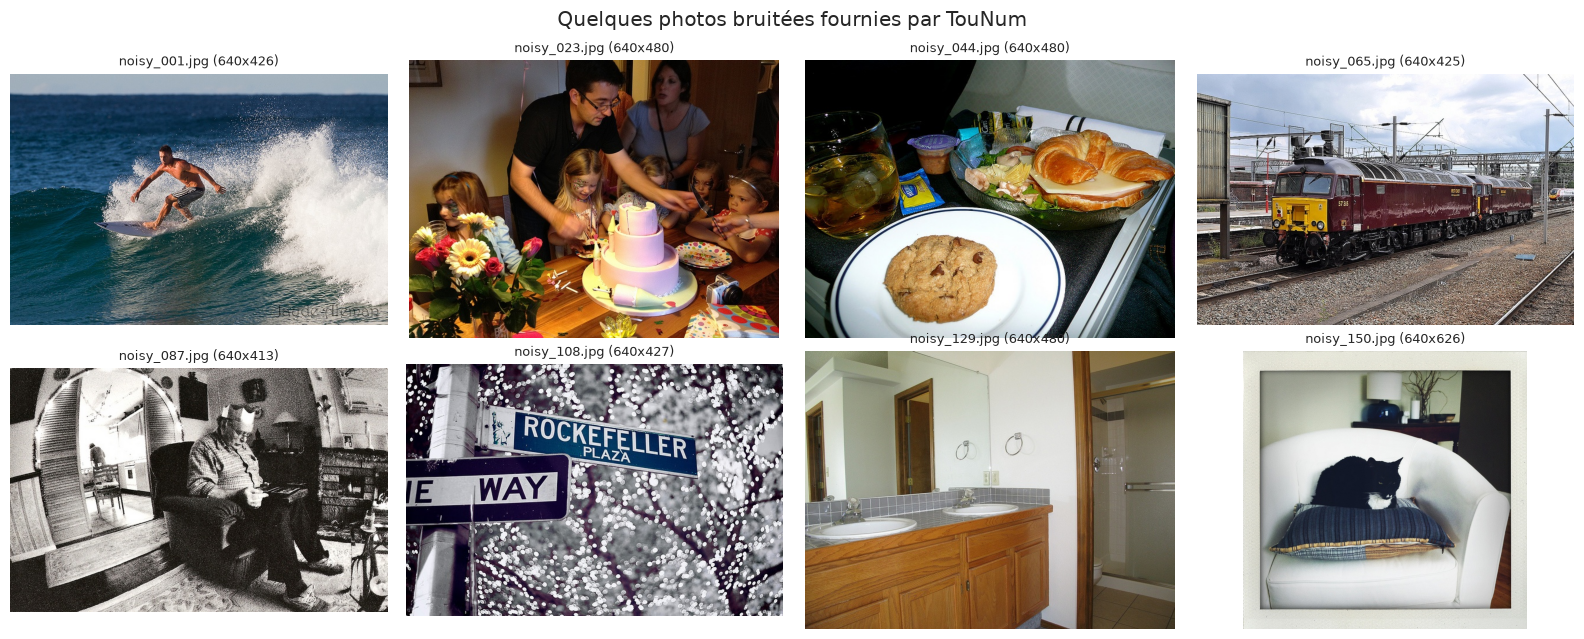

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, i in zip(axes.ravel(), np.linspace(0, len(noisy_images) - 1, 8).astype(int)):
    ax.imshow(noisy_images[i])
    ax.set_title(f"{noisy_info.file[i]} ({noisy_info.width[i]}x{noisy_info.height[i]})", fontsize=9)
    ax.axis("off")
plt.suptitle("Quelques photos bruitées fournies par TouNum")
plt.tight_layout()
plt.show()

À cette échelle, le bruit se voit à peine. Il apparaît quand on zoome sur une zone uniforme (ciel, mur, peau) :

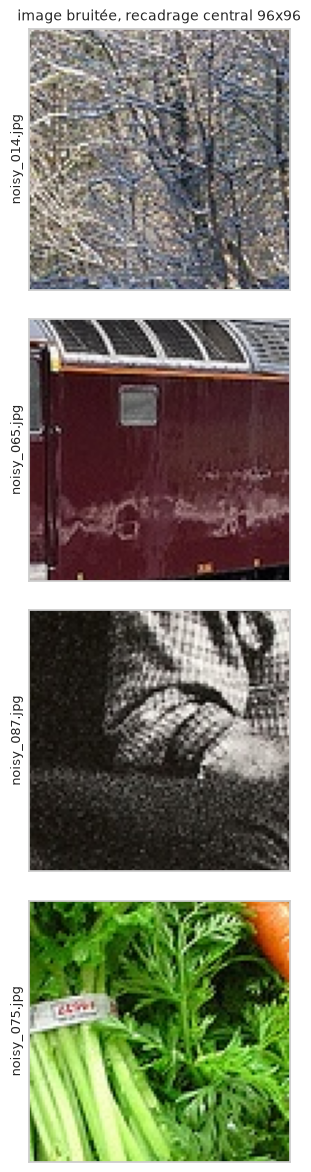

In [4]:
def center_crop(img, size=96):
    h, w = img.shape[:2]
    return img[h // 2 - size // 2: h // 2 + size // 2, w // 2 - size // 2: w // 2 + size // 2]


worst = noisy_info["noise_sigma"].nlargest(4).index
fig = evaluation.show_grid({"image bruitée, recadrage central 96x96": [center_crop(noisy_images[i]) for i in worst]},
                           [noisy_info.file[i] for i in worst], size=3)
plt.show()

## 3. Quel bruit ?

### 3.1 Les originaux propres
Ces photos font 640 pixels de large et ressemblent à des images de MS COCO, le dataset que nous utilisons pour le
captioning au livrable 3. En comparant de petites vignettes des fichiers bruités avec les images d'entraînement
de COCO 2017, nous l'avons confirmé : chaque fichier bruité a une correspondance exacte parmi les images COCO
d'identifiants 1308 à 2349 (`scripts/find_noisy_originals.py`, lancé une fois, résultat stocké dans
`src/tounum_denoise/noisy_originals.csv`).

Cela nous donne quelque chose de rare dans un projet de débruitage : la **vérité terrain propre** des vraies images
bruitées. Nous l'utilisons de trois façons :
- pour mesurer exactement le vrai bruit et construire un bruit d'entraînement qui lui ressemble (cette section) ;
- pour adapter les modèles au vrai bruit avec une partie des paires (section 9.2) ;
- pour évaluer les débruiteurs sur de vraies images qu'ils n'ont jamais vues (section 9), et pas seulement sur du
  bruit synthétique.

In [5]:
originals = data.load_originals(noisy_paths)
assert all(o.shape == n.shape for o, n in zip(originals, noisy_images))
residuals = [n.astype(np.float32) - o.astype(np.float32) for n, o in zip(noisy_images, originals)]
noisy_info["true_sigma"] = [r.std() for r in residuals]
noisy_info["psnr_noisy"] = [evaluation.psnr(data.to_float(o), data.to_float(n)) for o, n in zip(originals, noisy_images)]
display(noisy_info[["true_sigma", "noise_sigma", "psnr_noisy"]].describe().T)
print("true_sigma : vrai niveau de bruit (écart-type de la différence avec l'original) | noise_sigma : estimation "
      "sans l'original (section 3.3) | psnr_noisy : PSNR de l'image bruitée face à son original")

,count,mean,std,min,25%,50%,75%,max
true_sigma,148.0,3.463,1.557,0.607,2.400,3.174,4.316,9.750
noise_sigma,148.0,5.116,3.246,0.583,2.627,4.567,6.738,24.227
psnr_noisy,148.0,38.198,3.969,28.351,35.428,38.099,40.523,52.468


true_sigma : vrai niveau de bruit (écart-type de la différence avec l'original) | noise_sigma : estimation sans l'original (section 3.3) | psnr_noisy : PSNR de l'image bruitée face à son original


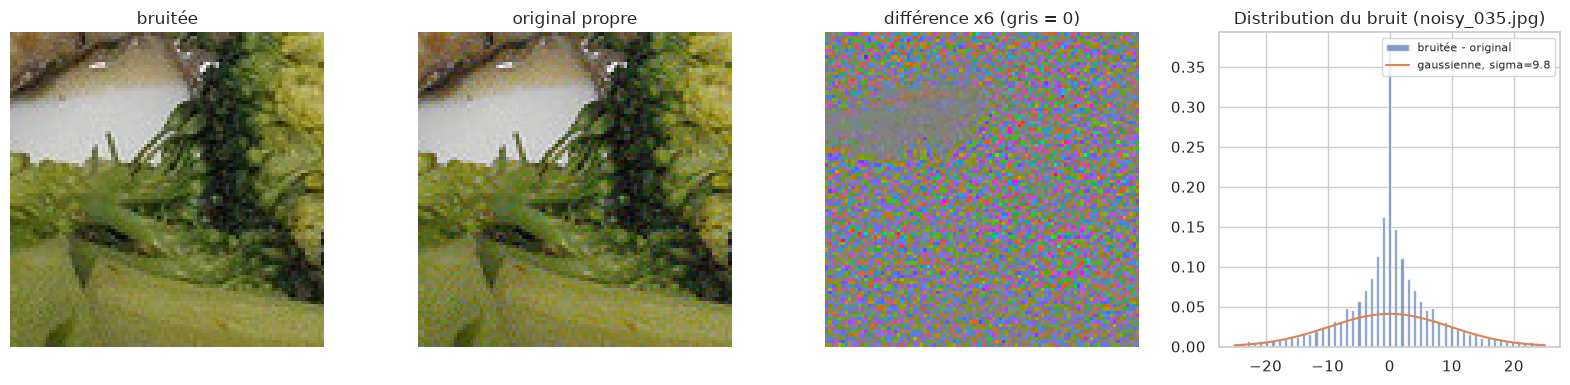

In [6]:
i = int(noisy_info["true_sigma"].idxmax())
r = residuals[i]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, img, title in zip(axes[:3], [center_crop(noisy_images[i]), center_crop(originals[i]),
                                     np.clip(center_crop(r) * 6 + 128, 0, 255).astype(np.uint8)],
                          ["bruitée", "original propre", "différence x6 (gris = 0)"]):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")
xs = np.linspace(-25, 25, 200)
axes[3].hist(r.ravel(), bins=101, range=(-25, 25), density=True, alpha=0.7, label="bruitée - original")
axes[3].plot(xs, np.exp(-xs**2 / (2 * r.std() ** 2)) / (r.std() * np.sqrt(2 * np.pi)), label=f"gaussienne, sigma={r.std():.1f}")
axes[3].set_title(f"Distribution du bruit ({noisy_info.file[i]})")
axes[3].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 3.2 Caractéristiques du vrai bruit
L'image de différence ci-dessus est colorée : le bruit semble modifier les couleurs plus que la luminosité. Pour
le vérifier, nous convertissons la différence dans l'espace **YCbCr** utilisé par JPEG, où Y est la luminosité et
Cb, Cr deux différences de couleur (bleu moins luminosité, rouge moins luminosité). Comme référence, nous
réencodons aussi chaque original propre en JPEG qualité 95, le format des fichiers bruités : cela donne l'erreur
ajoutée par le seul réencodage.

In [7]:
YCC = data.RGB_TO_YCBCR


def noise_profile(noisy, orig):
    """Où est le bruit (luminosité Y ou couleur Cb, Cr), quelle part de la couleur est conservée, et à quel point le
    bruit est lisse."""
    res = (noisy.astype(np.float32) - orig) @ YCC.T
    reenc = (data.jpeg_roundtrip(orig).astype(np.float32) - orig) @ YCC.T
    colour = (orig.astype(np.float32) @ YCC.T)[..., 1:].reshape(-1, 2)
    noisy_colour = colour + res[..., 1:].reshape(-1, 2)
    cb = res[..., 1]
    return {"moyenne (biais)": res.mean(), "écart-type Y": res[..., 0].std(),
            "écart-type Y, réencodage JPEG seul": reenc[..., 0].std(),
            "écart-type Cb": cb.std(), "écart-type Cr": res[..., 2].std(),
            "couleur conservée (pente)": (colour * noisy_colour).sum() / (colour * colour).sum(),
            "corrélation Cb entre voisins": np.corrcoef(cb[:, :-1].ravel(), cb[:, 1:].ravel())[0, 1]}


stats = pd.DataFrame([noise_profile(n, o) for n, o in zip(noisy_images, originals)])
display(stats.describe().T[["mean", "25%", "50%", "75%"]].rename(columns={"mean": "moyenne"}))


def jpeg_settings(source):
    """Pas de quantification moyen de la luminance et facteurs d'échantillonnage de la chrominance d'un fichier JPEG."""
    with Image.open(source) as im:
        return float(np.mean(im.quantization[0])), im.layer[1][1:3]


buf = io.BytesIO()
Image.fromarray(originals[0]).save(buf, format="JPEG", quality=95, subsampling=0)
file_settings = {jpeg_settings(p) for p in noisy_paths}
print(f"Réglages JPEG des 148 fichiers bruités (pas de quantification, échantillonnage chroma) : {file_settings}")
print(f"Réglages JPEG d'un réencodage en qualité 95 sans sous-échantillonnage chroma : {jpeg_settings(buf)}")

,moyenne,25%,50%,75%
moyenne (biais),0.006,-0.006,2.734e-04,0.008
écart-type Y,1.008,0.771,9.644e-01,1.238
"écart-type Y, réencodage JPEG seul",0.956,0.701,9.186e-01,1.192
écart-type Cb,2.469,1.509,2.352e+00,3.112
écart-type Cr,2.237,1.446,1.973e+00,2.783
couleur conservée (pente),0.850,0.928,9.650e-01,0.981
corrélation Cb entre voisins,0.445,0.354,4.511e-01,0.541


Réglages JPEG des 148 fichiers bruités (pas de quantification, échantillonnage chroma) : {(5.765625, (1, 1))}
Réglages JPEG d'un réencodage en qualité 95 sans sous-échantillonnage chroma : (5.765625, (1, 1))


On peut aussi comparer la force du bruit de couleur à la saturation de chaque pixel (la distance de (Cb, Cr) au
gris), une fois retirée la petite perte de couleur mesurée plus haut :

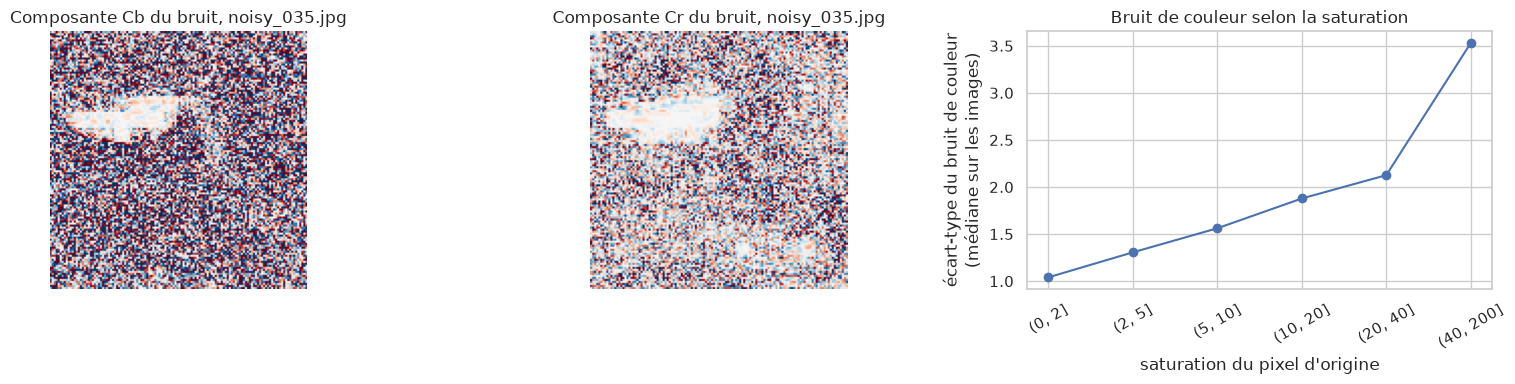

**Résultats.** Le bruit n'a pas de biais (moyenne +0.006). Dans le canal de luminosité Y, son écart-type vaut 0.96 (médiane sur les 148 images), autant qu'un simple réencodage JPEG de l'original (0.92) : **la luminosité n'est pas touchée**. Le bruit est dans les canaux de couleur (Cb 2.35, Cr 1.97). Les images bruitées gardent aussi 97% de la couleur d'origine (une légère perte de saturation), les pixels voisins partagent une partie de leur bruit (corrélation 0.45), et le bruit de couleur augmente avec la saturation, de 1.0 sur les pixels gris à 3.5 sur les plus colorés.

In [8]:
sat_bins = [0, 2, 5, 10, 20, 40, 200]
per_bin = []
for n, o in zip(noisy_images, originals):
    colour = (o.astype(np.float32) @ YCC.T)[..., 1:].reshape(-1, 2)
    noisy_colour = (n.astype(np.float32) @ YCC.T)[..., 1:].reshape(-1, 2)
    slope = (colour * noisy_colour).sum() / (colour * colour).sum()
    rest = np.hypot(*(noisy_colour - slope * colour).T) / np.sqrt(2)
    per_bin.append(pd.Series(rest).groupby(pd.cut(np.hypot(*colour.T), sat_bins), observed=False).mean())
by_saturation = pd.concat(per_bin, axis=1).median(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, k, name in zip(axes[:2], (1, 2), ("Cb", "Cr")):
    ax.imshow(center_crop(residuals[i] @ YCC.T, 128)[..., k], cmap="RdBu", vmin=-12, vmax=12)
    ax.set_title(f"Composante {name} du bruit, {noisy_info.file[i]}")
    ax.axis("off")
axes[2].plot([str(b) for b in by_saturation.index], by_saturation.to_numpy(), marker="o")
axes[2].set_xlabel("saturation du pixel d'origine")
axes[2].set_ylabel("écart-type du bruit de couleur\n(médiane sur les images)")
axes[2].set_title("Bruit de couleur selon la saturation")
axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

med = stats.median()
display(Markdown(
    f"**Résultats.** Le bruit n'a pas de biais (moyenne {stats['moyenne (biais)'].mean():+.3f}). Dans le canal de "
    f"luminosité Y, son écart-type vaut {med['écart-type Y']:.2f} (médiane sur les 148 images), autant qu'un simple "
    f"réencodage JPEG de l'original ({med['écart-type Y, réencodage JPEG seul']:.2f}) : **la luminosité n'est pas "
    f"touchée**. Le bruit est dans les canaux de couleur (Cb {med['écart-type Cb']:.2f}, Cr {med['écart-type Cr']:.2f}). "
    f"Les images bruitées gardent aussi {med['couleur conservée (pente)']:.0%} de la couleur d'origine (une légère "
    f"perte de saturation), les pixels voisins partagent une partie de leur bruit (corrélation "
    f"{med['corrélation Cb entre voisins']:.2f}), et le bruit de couleur augmente avec la saturation, de "
    f"{by_saturation.iloc[0]:.1f} sur les pixels gris à {by_saturation.iloc[-1]:.1f} sur les plus colorés."
))

Ce que les chiffres disent du bruit :
- il est de **moyenne nulle** et de forme à peu près **gaussienne** (l'histogramme de la section 3.1) ;
- il ne touche que les **couleurs** : la luminosité, qui porte les formes et les textures de l'image, est intacte ;
- il est **légèrement flou** (les pixels voisins sont corrélés) et **dépend de l'image** : il y a moins de bruit
  sur les zones grises que sur les couleurs saturées, et les couleurs sont un peu délavées ;
- son niveau **varie d'une image à l'autre** ;
- les fichiers ont été enregistrés en **JPEG qualité 95 sans sous-échantillonnage de la chrominance** (la table de
  quantification ci-dessus est la table standard mise à l'échelle pour la qualité 95), ce qui ajoute par-dessus une
  petite erreur de compression.

**Notre modèle de bruit pour l'entraînement** (`data.add_noise`) : un bruit gaussien ajouté aux deux seuls canaux
de couleur Cb et Cr, flouté par un petit noyau gaussien 3×3 pour que les pixels voisins soient corrélés comme dans
le vrai bruit, avec un écart-type tiré uniformément entre 0 et 20 pour chaque image, suivi d'un réencodage JPEG en
qualité 95. La plage dépasse largement les niveaux réels pour que le modèle sache aussi traiter des images plus
bruitées. Ce modèle laisse de côté deux détails du vrai bruit, la perte de saturation et le bruit plus fort sur les
couleurs saturées. Plutôt que de les modéliser à la main, nous adaptons les modèles avec des paires réelles en
section 9.2.

### 3.3 Estimer le niveau de bruit sans l'original
En production, il n'y a pas d'original propre. Pour décider si une image doit être débruitée, nous utilisons
l'**estimateur d'Immerkaer** : un noyau de convolution 3×3 qui annule le contenu lisse de l'image (c'est la
différence de deux laplaciens), de sorte qu'il reste surtout du bruit ; la moyenne de sa réponse en valeur absolue
donne l'écart-type du bruit. Les textures détaillées (herbe, fourrure) passent aussi à travers le noyau, donc
l'estimation est trop haute sur les images texturées.

Noyau d'Immerkaer :
 [[ 1 -2  1]
 [-2  4 -2]
 [ 1 -2  1]]


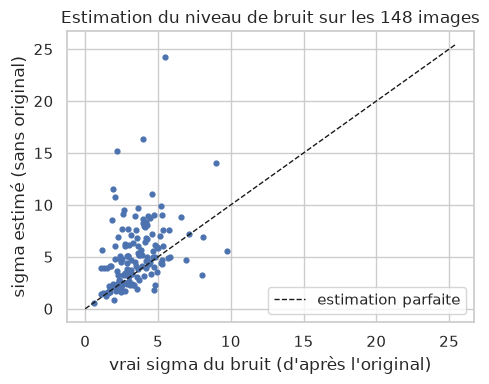

**Résultats.** Vrai niveau de bruit des 148 images (écart-type de la différence, en RGB) : médiane **3.2**, maximum **9.8** ; PSNR des images bruitées face à leurs originaux : médiane **38.1 dB** (de 28.4 à 52.5 dB). Le bruit est léger : au-dessus de 35 dB, une personne le voit à peine à taille normale. L'estimation à l'aveugle n'est que faiblement liée au vrai niveau (r = 0.38), et sur les originaux **propres** elle donne une médiane de 4.5, contre 4.6 sur les fichiers bruités : à ce niveau de bruit, les textures de l'image pèsent plus dans l'estimation que le bruit lui-même. La section 9.3 en tient compte.

In [9]:
print("Noyau d'Immerkaer :\n", data._IMMERKAER.astype(int))
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(noisy_info["true_sigma"], noisy_info["noise_sigma"], s=12)
lim = max(noisy_info["true_sigma"].max(), noisy_info["noise_sigma"].max()) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=1, label="estimation parfaite")
ax.set_xlabel("vrai sigma du bruit (d'après l'original)")
ax.set_ylabel("sigma estimé (sans original)")
ax.set_title("Estimation du niveau de bruit sur les 148 images")
ax.legend()
plt.tight_layout()
plt.show()
corr = np.corrcoef(noisy_info["true_sigma"], noisy_info["noise_sigma"])[0, 1]
orig_estimate = np.median([data.estimate_noise(o) for o in originals])
display(Markdown(
    f"**Résultats.** Vrai niveau de bruit des 148 images (écart-type de la différence, en RGB) : médiane "
    f"**{noisy_info['true_sigma'].median():.1f}**, maximum **{noisy_info['true_sigma'].max():.1f}** ; PSNR des images "
    f"bruitées face à leurs originaux : médiane **{noisy_info['psnr_noisy'].median():.1f} dB** (de "
    f"{noisy_info['psnr_noisy'].min():.1f} à {noisy_info['psnr_noisy'].max():.1f} dB). Le bruit est léger : au-dessus "
    "de 35 dB, une personne le voit à peine à taille normale. L'estimation à l'aveugle n'est que faiblement liée au "
    f"vrai niveau (r = {corr:.2f}), et sur les originaux **propres** elle donne une médiane de {orig_estimate:.1f}, "
    f"contre {noisy_info['noise_sigma'].median():.1f} sur les fichiers bruités : à ce niveau de bruit, les textures "
    "de l'image pèsent plus dans l'estimation que le bruit lui-même. La section 9.3 en tient compte."
))

## 4. Données d'entraînement

Un autoencodeur apprend à débruiter à partir de paires (image bruitée, image propre). Nous entraînons les modèles
en deux temps : d'abord sur beaucoup de photos propres avec le bruit synthétique de la section 3 (ce qui donne un
débruiteur de couleur généraliste), puis nous les adaptons avec un petit nombre de vraies paires TouNum
(section 9.2).

### 4.1 Photos propres avec bruit synthétique
- **Photos propres** : les photos du livrable 1 (`Dataset Livrable 1 - Photo.zip`, déjà extraites et
  échantillonnées là-bas). Le jeu d'entraînement du livrable 1 sert à l'entraînement, son jeu de validation à la
  validation. Son jeu de test reste inédit et sert en section 9.
- **Patchs** : nous découpons 8 patchs 96×96 au hasard dans chaque photo. Le réseau est entièrement convolutif :
  il apprend sur de petits patchs puis fonctionne sur des images de n'importe quelle taille. Les photos gardent
  leur résolution (la plupart font 640×480, comme les images TouNum) ; seules les quelques plus grandes sont
  réduites à 480 pixels sur leur petit côté. Notre première version, entraînée sur CPU, réduisait toutes les photos
  à 320 pixels, prenait 4 patchs par photo et au plus 25 époques pour garder un temps d'entraînement raisonnable.
  L'entraînement tourne maintenant sur GPU : nous gardons la résolution native (plus proche des images à
  débruiter), prenons deux fois plus de patchs et laissons l'early stopping décider quand s'arrêter, jusqu'à
  60 époques.
- **Bruit tiré à la volée** : dans le pipeline d'entraînement (`tf.data`), chaque patch reçoit à chaque époque un
  nouveau niveau de bruit, un nouveau bruit et un retournement horizontal aléatoire. Le bruit de validation est
  tiré une seule fois avec une graine fixe, pour que les scores de validation soient comparables d'une époque (et
  d'un modèle) à l'autre.

In [10]:
meta = pd.read_csv(cls_config.CACHE_DIR / "meta.csv")
photos = meta[meta["source"] == cls_config.POSITIVE_CLASS]
photo_paths = {s: [cls_config.PROJECT_ROOT / p for p in photos.loc[photos["split"] == s, "path"]] for s in ("train", "val", "test")}
print({s: len(p) for s, p in photo_paths.items()}, "photos du livrable 1 par jeu")

t0 = time.perf_counter()
train_patches = data.cached_patches("train", photo_paths["train"])
val_patches = data.cached_patches("val", photo_paths["val"], crops_per_image=2, seed=config.SEED + 1)
if QUICK:
    train_patches, val_patches = train_patches[:640], val_patches[:128]
print(f"patchs d'entraînement {train_patches.shape}, patchs de validation {val_patches.shape} ({time.perf_counter() - t0:.0f} s)")

train_ds = data.make_dataset(train_patches)
val_noisy, val_clean, val_sigma = data.fixed_noisy_set(val_patches)

{'train': 4200, 'val': 900, 'test': 900} photos du livrable 1 par jeu
patchs d'entraînement (33600, 96, 96, 3), patchs de validation (1800, 96, 96, 3) (0 s)


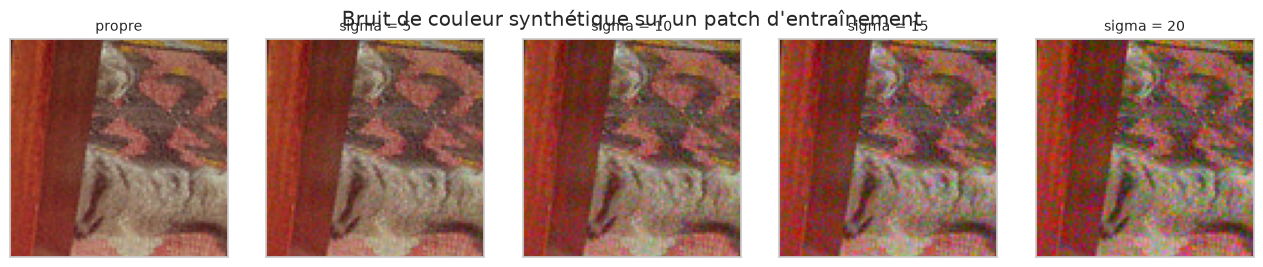

In [11]:
rng = np.random.default_rng(config.SEED)
example = train_patches[7]
cols = {"propre": [example]}
for s in (5, 10, 15, 20):
    cols[f"sigma = {s}"] = [data.add_noise(example, s, rng)]
evaluation.show_grid(cols, size=2.6)
plt.suptitle("Bruit de couleur synthétique sur un patch d'entraînement", y=1.02)
plt.show()

### 4.2 Paires réelles et photos propres
Les 148 paires (bruitée, original) sont découpées une fois, au hasard avec une graine fixe : 78 images pour adapter
les modèles (fine-tuning), 20 pour valider cette étape et choisir le modèle final et la règle de décision, et
**50 images de test mises de côté** jusqu'à la mesure finale (section 9). Dans les images de fine-tuning et de
validation, nous découpons des recadrages 96×96 alignés de l'image bruitée et de son original.

En production, le débruiteur recevra aussi des photos propres, et peut-être des photos plus bruitées que ces 148.
Le jeu de fine-tuning reçoit donc deux autres parties de même taille : des recadrages de photos propres (issues du
jeu d'entraînement du livrable 1) dont la cible est l'entrée elle-même, et des patchs avec le bruit synthétique de
la section 4.1. Le modèle doit apprendre à retirer le bruit TouNum, à laisser les photos propres tranquilles, et à
garder ce qu'il a appris sur des bruits plus forts. Le jeu de validation mélange les trois types de recadrages de
la même façon.

In [12]:
real_split = data.split_real_pairs(noisy_info["file"].tolist())
real_idx = {k: [int(np.flatnonzero(noisy_info["file"] == f)[0]) for f in files] for k, files in real_split.items()}
n_crops = 8 if QUICK else config.REAL_CROPS_PER_IMAGE
ft_noisy, ft_clean = data.pair_crops([noisy_images[i] for i in real_idx["finetune"]],
                                     [originals[i] for i in real_idx["finetune"]], n=n_crops)
rv_noisy, rv_clean = data.pair_crops([noisy_images[i] for i in real_idx["val"]],
                                     [originals[i] for i in real_idx["val"]], n=n_crops // 4, seed=config.SEED + 1)
n_clean_ft = 50 if QUICK else config.CLEAN_FT_PHOTOS
clean_ft = data.build_patches(photo_paths["train"][:n_clean_ft], crops_per_image=10)
clean_v = data.build_patches(photo_paths["val"][:n_clean_ft // 10], crops_per_image=6, seed=config.SEED + 2)
syn_clean = train_patches[:len(ft_noisy)]                                   # bruit tiré une fois, avec graine
syn_noisy = data.to_uint8(data.fixed_noisy_set(syn_clean, seed=config.SEED + 3)[0])
n_sv = min(len(rv_noisy), len(val_patches))
mix_noisy = np.concatenate([ft_noisy, clean_ft, syn_noisy])
mix_clean = np.concatenate([ft_clean, clean_ft, syn_clean])
mix_val = (np.concatenate([data.to_float(rv_noisy), data.to_float(clean_v), val_noisy[:n_sv]]),
           np.concatenate([data.to_float(rv_clean), data.to_float(clean_v), val_clean[:n_sv]]))
display(pd.DataFrame({"images": [len(real_split["finetune"]), n_clean_ft, "", len(real_split["val"]), n_clean_ft // 10,
                                 "", len(real_split["test"])],
                      "recadrages 96x96": [len(ft_noisy), len(clean_ft), len(syn_noisy), len(rv_noisy), len(clean_v), n_sv, 0]},
                     index=["fine-tuning, paires TouNum", "fine-tuning, photos propres", "fine-tuning, bruit synthétique",
                            "validation, paires TouNum", "validation, photos propres", "validation, bruit synthétique",
                            "test, paires TouNum"]))

,images,recadrages 96x96
"fine-tuning, paires TouNum",78,9984
"fine-tuning, photos propres",1000,10000
"fine-tuning, bruit synthétique",,9984
"validation, paires TouNum",20,640
"validation, photos propres",100,600
"validation, bruit synthétique",,640
"test, paires TouNum",50,0


## 5. Point de comparaison : les filtres de convolution classiques

Avant d'entraîner quoi que ce soit, il nous faut un point de référence. Les débruiteurs les plus simples sont les
**filtres de convolution** : chaque pixel de sortie est une moyenne pondérée de ses voisins, ce qui moyenne le
bruit mais floute aussi les contours.
- **Filtre moyenne** : tous les pixels d'une fenêtre k×k ont le même poids.
- **Filtre gaussien** : les pixels proches pèsent plus (poids gaussiens), il floute donc un peu moins pour le même
  effet.
- **Filtre médian** (ce n'est pas une convolution) : prend la médiane de la fenêtre, ce qui garde des contours plus
  nets et fonctionne très bien contre les valeurs aberrantes isolées (bruit poivre et sel).

In [13]:
print("Noyau moyenne 3x3 :\n", evaluation.mean_kernel(3).round(3))
print("Noyau gaussien, sigma = 1 (7x7) :\n", evaluation.gaussian_kernel(1.0).round(3))

Noyau moyenne 3x3 :
 [[0.111 0.111 0.111]
 [0.111 0.111 0.111]
 [0.111 0.111 0.111]]
Noyau gaussien, sigma = 1 (7x7) :
 [[0.    0.    0.001 0.002 0.001 0.    0.   ]
 [0.    0.003 0.013 0.022 0.013 0.003 0.   ]
 [0.001 0.013 0.059 0.097 0.059 0.013 0.001]
 [0.002 0.022 0.097 0.159 0.097 0.022 0.002]
 [0.001 0.013 0.059 0.097 0.059 0.013 0.001]
 [0.    0.003 0.013 0.022 0.013 0.003 0.   ]
 [0.    0.    0.001 0.002 0.001 0.    0.   ]]


In [14]:
def score(name, pred, clean=val_clean, sigma=val_sigma):
    """PSNR / SSIM par patch d'une méthode de débruitage sur le jeu de validation."""
    return pd.DataFrame({"méthode": name, "sigma": sigma, "psnr": evaluation.psnr(clean, pred),
                         "ssim": evaluation.ssim(clean, pred)})


val_scores = [score(NOISY, val_noisy)]
for name, f in evaluation.CLASSICAL_FILTERS.items():
    val_scores.append(score(name, f(val_noisy)))
filter_table = pd.concat(val_scores).groupby("méthode", sort=False)[["psnr", "ssim"]].mean()
display(filter_table)
best_filter = filter_table.drop(index=NOISY)["psnr"].idxmax()

,psnr,ssim
méthode,,
bruitée (sans filtre),27.101,0.644
moyenne 3x3,26.533,0.678
moyenne 5x5,25.373,0.626
gaussien s=1,26.921,0.711
médian 3x3,26.691,0.668
médian 5x5,25.919,0.641


Le **PSNR** (peak signal-to-noise ratio, en dB) mesure l'erreur sur les pixels par rapport à l'image propre :
$\mathrm{PSNR} = 10 \log_{10}(1 / \mathrm{MSE})$ pour des pixels dans [0, 1]. +3 dB signifie que l'erreur
quadratique est divisée par deux. Le **SSIM** (similarité structurelle, de 0 à 1) compare la luminosité, le
contraste et la structure locale, et se rapproche davantage de la perception humaine. Les deux sont moyennés sur
les patchs de validation, dont le niveau de bruit est réparti entre 0 et 20. À noter : les filtres floutent aussi
la luminosité, alors que le bruit n'est que dans les couleurs.

## 6. Autoencodeurs convolutifs

Un **autoencodeur** est un réseau entraîné à produire une image à partir d'une image d'entrée. L'**encodeur**
compresse l'image en une représentation plus petite (moins de pixels, plus de canaux), et le **décodeur**
reconstruit une image pleine taille à partir de celle-ci. Pour le débruitage, l'entrée est l'image bruitée et la
cible l'image propre : le réseau doit apprendre ce qui appartient à l'image et ce qui est du bruit.

Nous comparons trois variantes construites par la même fonction :
1. **Autoencodeur convolutif simple** : tout passe par le goulot d'étranglement, au quart de la résolution.
2. **Autoencodeur avec connexions de saut** (style U-Net) : chaque niveau de l'encodeur est aussi transmis
   directement au niveau du décodeur de même résolution. Les détails fins (contours, textures) n'ont plus à passer
   par le goulot, et le décodeur peut se concentrer sur le retrait du bruit.
3. **Connexions de saut et sortie résiduelle** : la dernière couche prédit le *bruit* au lieu de l'image propre,
   et la sortie est l'entrée moins ce bruit (l'idée du réseau DnCNN). Pour laisser une zone propre intacte, le
   réseau n'a qu'à prédire zéro ; les deux autres variantes doivent reconstruire chaque pixel, ce qui coûte
   toujours un peu de précision. C'est important pour les images TouNum, dont le bruit est léger.

In [15]:
print(inspect.getsource(modeling.build_autoencoder))

def build_autoencoder(
    filters: tuple[int, ...] = (32, 64, 128),
    skips: bool = False,
    residual: bool = False,
    learning_rate: float = 1e-3,
    name: str | None = None,
) -> keras.Model:
    """Autoencodeur convolutif qui transforme une image RGB bruitée en image propre (float32 dans [0, 1]).

    Encodeur : à chaque niveau, deux Conv2D 3x3 + ReLU, puis MaxPooling2D 2x2 (le dernier niveau est le goulot
    d'étranglement, sans pooling). Décodeur : Conv2DTranspose 2x2 stride 2 (suréchantillonnage) puis deux Conv2D
    3x3, symétrique de l'encodeur. Sortie : Conv2D 1x1 à 3 canaux et sigmoïde.
    `skips=True` concatène chaque niveau de l'encodeur avec le niveau du décodeur de même résolution (style
    U-Net), pour que les détails fins n'aient pas à passer par le goulot basse résolution.
    `residual=True` fait prédire le bruit à la dernière Conv2D 1x1 au lieu de l'image propre ; la sortie est
    l'entrée bruitée moins ce bruit, ramenée dans [0, 1]. Laisser une image int

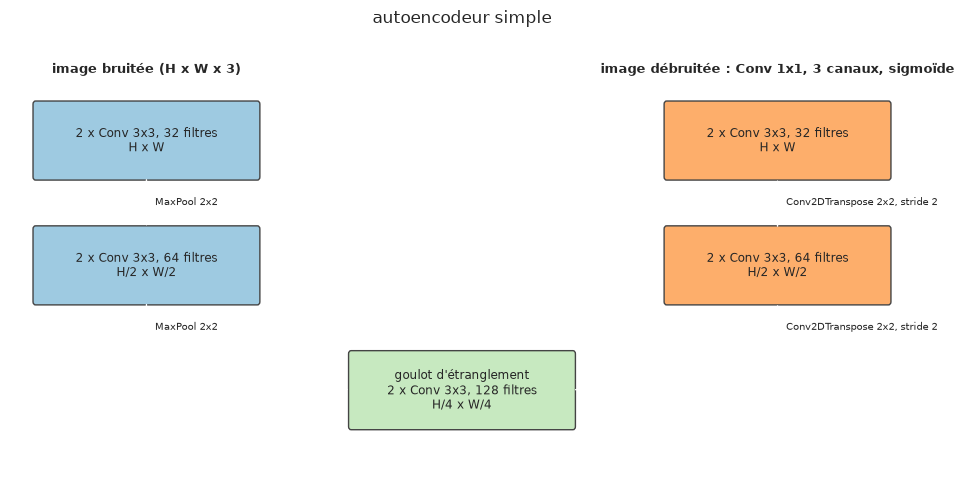

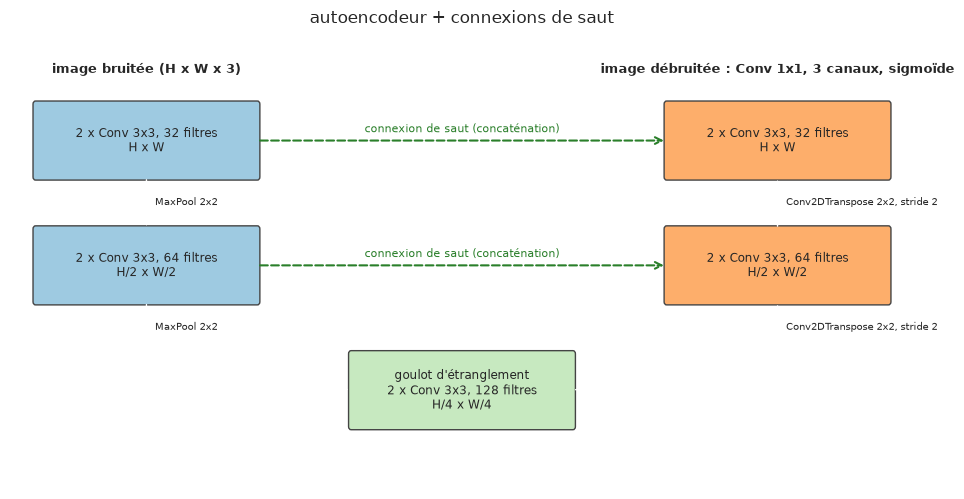

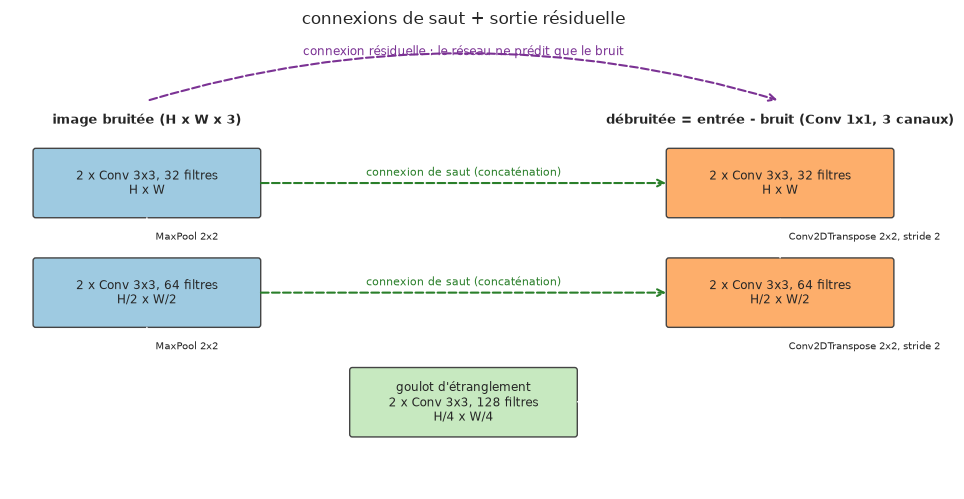

In [16]:
VARIANTS = {"autoencodeur simple": dict(skips=False),
            "autoencodeur + connexions de saut": dict(skips=True),
            "connexions de saut + sortie résiduelle": dict(skips=True, residual=True)}
for name, kwargs in VARIANTS.items():
    evaluation.draw_autoencoder((32, 64, 128), title=name, **kwargs)
    plt.show()

In [17]:
keras.utils.set_random_seed(config.SEED)
modeling.build_autoencoder(skips=True, residual=True).summary()

Model: "residual_unet_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ noisy (InputLayer)  │ (None, None,      │          0 │ -                 │
│                     │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv1 (Conv2D) │ (None, None,      │        896 │ noisy[0][0]       │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv2 (Conv2D) │ (None, None,      │      9,248 │ enc1_conv1[0][0]  │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_pool           │ (None, None,      │          0 │ enc1_conv2[0][0]  │
│ (MaxPooling2D)      │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_conv1 (Conv2D) │ (None, None,      │     18,496 │ enc1_pool[0][0]   │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_conv2 (Conv2D) │ (None, None,      │     36,928 │ enc2_conv1[0][0]  │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_pool           │ (None, None,      │          0 │ enc2_conv2[0][0]  │
│ (MaxPooling2D)      │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_conv1    │ (None, None,      │     73,856 │ enc2_pool[0][0]   │
│ (Conv2D)            │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_conv2    │ (None, None,      │    147,584 │ bottleneck_conv1… │
│ (Conv2D)            │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec2_up             │ (None, None,      │     32,832 │ bottleneck_conv2… │
│ (Conv2DTranspose)   │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec2_skip           │ (None, None,      │          0 │ dec2_up[0][0],    │
│ (Concatenate)       │ None, 128)        │            │ enc2_conv2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec2_conv1 (Conv2D) │ (None, None,      │     73,792 │ dec2_skip[0][0]   │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec2_conv2 (Conv2D) │ (None, None,      │     36,928 │ dec2_conv1[0][0]  │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec1_up             │ (None, None,      │      8,224 │ dec2_conv2[0][0]  │
│ (Conv2DTranspose)   │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec1_skip           │ (None, None,      │          0 │ dec1_up[0][0],    │
│ (Concatenate)       │ None, 64)         │            │ enc1_conv2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec1_conv1 (Conv2D) │ (None, None,      │     18,464 │ dec1_skip[0][0]   │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec1_conv2 (Conv2D) │ (None, None,      │      9,248 │ dec1_conv1[0][0]

 Total params: 466,595 (1.78 MB)

 Trainable params: 466,595 (1.78 MB)

 Non-trainable params: 0 (0.00 B)

### 6.1 Paramètres, perte et optimiseur

| Élément | Choix | Raison |
|---|---|---|
| Entrée / sortie | image RGB, valeurs flottantes dans [0, 1], toute taille (multiple de 4) | entièrement convolutif, pas de couche dense |
| Convolutions | 3×3, ReLU, padding `same`, 32 / 64 / 128 filtres | brique standard ; le champ récepteur grandit à chaque niveau |
| Sous-échantillonnage / suréchantillonnage | MaxPooling 2×2 / Conv2DTranspose 2×2 stride 2 | divise / double la résolution, la convolution transposée apprend à suréchantillonner |
| Sortie | Conv 1×1, 3 canaux, sigmoïde ; pour la variante résiduelle, Conv 1×1 qui prédit le bruit, soustrait de l'entrée et ramené dans [0, 1] | garde les pixels dans [0, 1] |
| **Perte** | **erreur quadratique moyenne** $\frac{1}{N}\sum (\hat{x} - x)^2$ entre la sortie et l'image propre | directement liée au PSNR, que nous cherchons à augmenter |
| **Optimiseur** | **Adam**, taux d'apprentissage $10^{-3}$, batchs de 32 patchs | choix par défaut fiable, pas de réglage du taux d'apprentissage nécessaire |
| Régularisation | early stopping (patience 6) sur la perte de validation, meilleurs poids restaurés | s'arrête quand la validation ne progresse plus |
| Métriques suivies | PSNR et SSIM | les mesures de qualité définies en section 5 |

Les trois modèles ont à peu près le même nombre de paramètres (environ 420 000 pour le simple, 467 000 pour les
deux autres) : les connexions de saut n'ajoutent des canaux qu'à la première convolution de chaque niveau du
décodeur, et la sortie résiduelle a la même taille que la sortie sigmoïde.

## 7. Entraînement et courbes d'apprentissage

In [18]:
histories, models_, times = {}, {}, {}
for name, kwargs in VARIANTS.items():
    keras.utils.set_random_seed(config.SEED)
    model = modeling.build_autoencoder(**kwargs)
    t0 = time.perf_counter()
    histories[name] = modeling.train(model, train_ds, (val_noisy, val_clean), epochs=EPOCHS, patience=6, verbose=0)
    times[name] = time.perf_counter() - t0
    models_[name] = model
    print(f"{name} : {len(histories[name])} époques en {times[name] / 60:.1f} min")

autoencodeur simple : 31 époques en 3.5 min


autoencodeur + connexions de saut : 27 époques en 3.1 min


connexions de saut + sortie résiduelle : 34 époques en 3.9 min


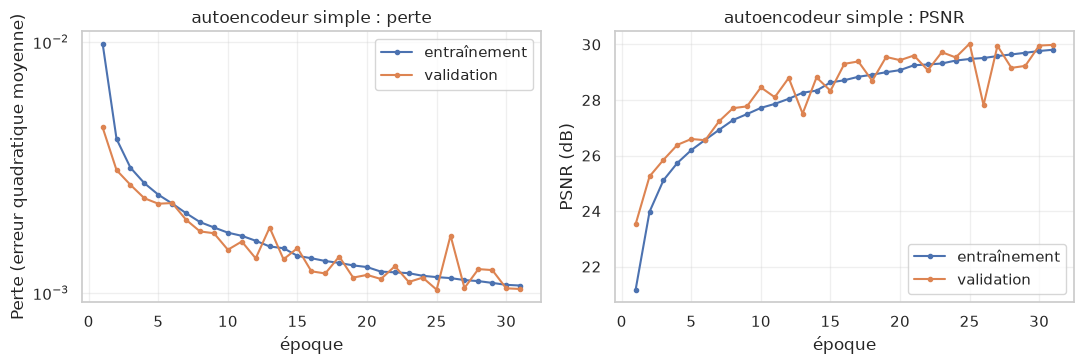

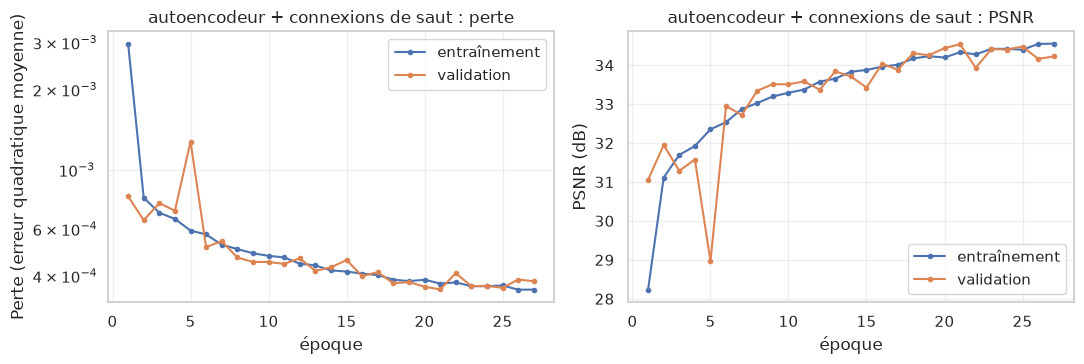

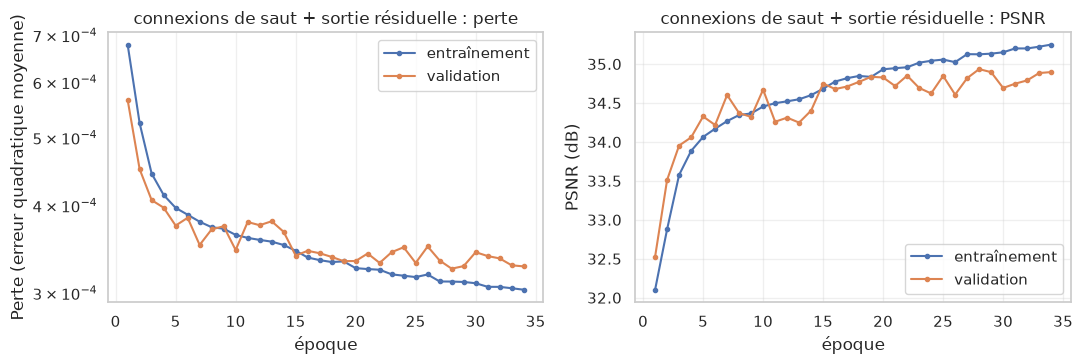

In [19]:
for name, hist in histories.items():
    evaluation.plot_history(hist, name)
    plt.show()

In [20]:
rows = []
for name, hist in histories.items():
    best = hist.loc[hist["val_loss"].idxmin()]
    rows.append({"modèle": name, "paramètres": models_[name].count_params(), "époques effectuées": len(hist),
                 "meilleure époque": int(best["epoch"]), "PSNR entraînement": best["psnr"], "PSNR validation": best["val_psnr"],
                 "SSIM validation": best["val_ssim"], "écart PSNR entr. - val.": best["psnr"] - best["val_psnr"],
                 "temps (min)": times[name] / 60})
train_table = pd.DataFrame(rows).set_index("modèle")
display(train_table)
chosen = train_table["PSNR validation"].idxmax()
gap = train_table.loc[chosen, "écart PSNR entr. - val."]
display(Markdown(
    f"**Résultats.** Meilleur PSNR de validation sur bruit synthétique : **{chosen}**, avec "
    f"**{train_table.loc[chosen, 'PSNR validation']:.2f} dB** (SSIM {train_table.loc[chosen, 'SSIM validation']:.3f}), "
    "contre "
    + ", ".join(f"{train_table.loc[n, 'PSNR validation']:.2f} dB pour « {n} »" for n in train_table.index if n != chosen)
    + f" et {filter_table.loc[best_filter, 'psnr']:.2f} dB pour le meilleur filtre classique ({best_filter}). "
    f"Le PSNR d'entraînement et celui de validation de ce modèle diffèrent de {gap:+.2f} dB"
    + (" : pas de signe de sur-apprentissage, le modèle pourrait sans doute profiter de plus de capacité ou "
       "d'époques (côté biais)."
       if abs(gap) < 0.5 else
       (" : l'entraînement est nettement meilleur que la validation, signe de sur-apprentissage (côté variance)."
        if gap > 0
        else " : la validation est meilleure que l'entraînement. Le PSNR d'entraînement est moyenné sur l'époque "
             "pendant que les poids changent encore, et le bruit d'entraînement est retiré à chaque époque : ce "
             "n'est donc pas un problème."))
))

,paramètres,époques effectuées,meilleure époque,PSNR entraînement,PSNR validation,SSIM validation,écart PSNR entr. - val.,temps (min)
modèle,,,,,,,,
autoencodeur simple,420515,31,25,29.477,30.030,0.904,-0.553,3.481
autoencodeur + connexions de saut,466595,27,21,34.334,34.539,0.951,-0.204,3.096
connexions de saut + sortie résiduelle,466595,34,28,35.125,34.935,0.954,0.190,3.864


**Résultats.** Meilleur PSNR de validation sur bruit synthétique : **connexions de saut + sortie résiduelle**, avec **34.93 dB** (SSIM 0.954), contre 30.03 dB pour « autoencodeur simple », 34.54 dB pour « autoencodeur + connexions de saut » et 26.92 dB pour le meilleur filtre classique (gaussien s=1). Le PSNR d'entraînement et celui de validation de ce modèle diffèrent de +0.19 dB : pas de signe de sur-apprentissage, le modèle pourrait sans doute profiter de plus de capacité ou d'époques (côté biais).

**Lecture des courbes.** Le bruit d'entraînement est nouveau à chaque époque, donc le réseau ne peut pas apprendre
par cœur des patchs bruités : chaque patch revient avec un bruit différent, le sur-apprentissage est peu probable
et les courbes d'entraînement et de validation restent proches. Si un écart apparaissait, les remèdes habituels
seraient plus de photos, plus d'augmentation (rotations, changements de couleur) ou du weight decay. Un
autoencodeur simple doit tout faire passer par son goulot, au quart de la résolution, et a donc tendance à perdre
les détails fins : un problème de biais que plus de données ne corrigerait pas, et que les connexions de saut
doivent supprimer. La cellule suivante le vérifie sur nos entraînements.

In [21]:
plain, skip = train_table.loc["autoencodeur simple"], train_table.loc["autoencodeur + connexions de saut"]
display(Markdown(
    f"**Résultats.** À leur meilleure époque, l'autoencodeur simple atteint {plain['PSNR entraînement']:.2f} dB en "
    f"entraînement et {plain['PSNR validation']:.2f} dB en validation ; avec connexions de saut, "
    f"{skip['PSNR entraînement']:.2f} dB et {skip['PSNR validation']:.2f} dB. "
    + ("L'autoencodeur simple plafonne plus bas sur les deux jeux : c'est le problème de biais décrit plus haut."
       if plain["PSNR validation"] < skip["PSNR validation"] and plain["PSNR entraînement"] < skip["PSNR entraînement"] else
       "Lors de cette exécution, l'autoencodeur simple ne plafonne pas plus bas que la version avec connexions de "
       "saut : ce n'est donc pas le goulot qui le limite.")
))

**Résultats.** À leur meilleure époque, l'autoencodeur simple atteint 29.48 dB en entraînement et 30.03 dB en validation ; avec connexions de saut, 34.33 dB et 34.54 dB. L'autoencodeur simple plafonne plus bas sur les deux jeux : c'est le problème de biais décrit plus haut.

## 8. Évaluation par niveau de bruit

Débruiter est facile quand il y a peu de bruit et difficile quand il y en a beaucoup : une seule moyenne cache donc
beaucoup de choses. Nous ajoutons maintenant du bruit à des niveaux fixes aux patchs de validation et comparons
toutes les méthodes à chaque niveau. Le niveau 0 vérifie qu'une image propre n'est pas abîmée. Ici le PSNR est
calculé à partir de l'erreur quadratique moyenne sur tous les patchs : certains patchs uniformes (blanc pur)
sortent de l'étape JPEG inchangés au niveau 0, et leur PSNR propre serait infini.

sigma,0,5,10,15,20
méthode,,,,,
autoencodeur + connexions de saut,37.31,35.82,34.52,33.53,32.47
autoencodeur simple,30.31,30.21,29.96,29.61,29.17
bruitée (sans filtre),40.33,30.47,25.29,22.11,19.84
connexions de saut + sortie résiduelle,38.99,36.41,34.80,33.76,32.70
gaussien s=1,25.84,25.62,25.06,24.29,23.43


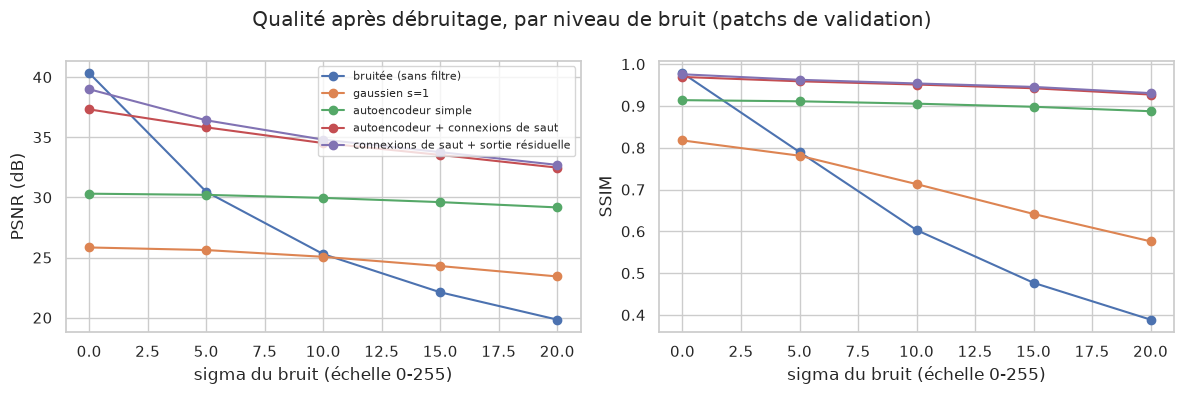

In [22]:
def all_methods(noisy):
    """Sorties de toutes les méthodes sur un batch de patchs bruités (flottants)."""
    outs = {NOISY: noisy, best_filter: evaluation.CLASSICAL_FILTERS[best_filter](noisy)}
    for name, model in models_.items():
        outs[name] = modeling.predict(model, noisy)
    return outs


level_rows, level_examples = [], {}
for s in config.SIGMA_LEVELS:
    rng = np.random.default_rng(config.SEED + s)
    noisy = data.to_float(np.stack([data.add_noise(p, s, rng) for p in val_patches]))
    for name, out in all_methods(noisy).items():
        level_rows.append({"sigma": s, "méthode": name, "PSNR": evaluation.dataset_psnr(val_clean, out),
                           "SSIM": evaluation.ssim(val_clean, out).mean()})
        level_examples[(s, name)] = out[11]
level_df = pd.DataFrame(level_rows)
display(level_df.pivot(index="méthode", columns="sigma", values="PSNR").round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, grp in level_df.groupby("méthode", sort=False):
    axes[0].plot(grp["sigma"], grp["PSNR"], marker="o", label=name)
    axes[1].plot(grp["sigma"], grp["SSIM"], marker="o", label=name)
axes[0].set_ylabel("PSNR (dB)")
axes[1].set_ylabel("SSIM")
for ax in axes:
    ax.set_xlabel("sigma du bruit (échelle 0-255)")
axes[0].legend(fontsize=8)
plt.suptitle("Qualité après débruitage, par niveau de bruit (patchs de validation)")
plt.tight_layout()
plt.show()

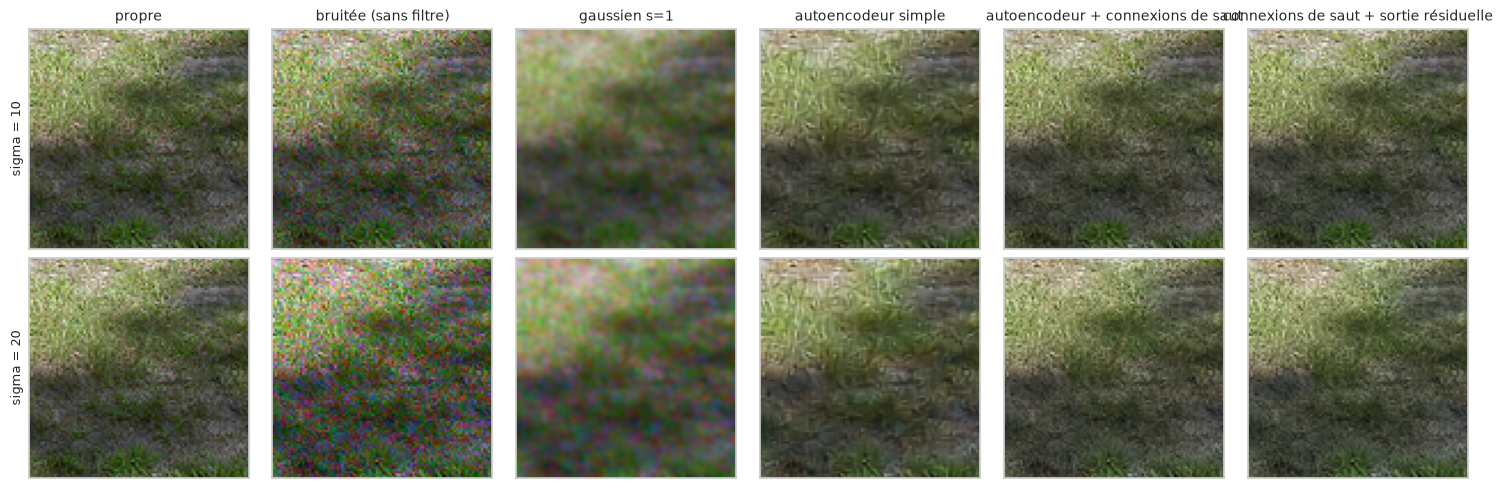

In [23]:
methods = list(all_methods(val_noisy[:1]).keys())
cols = {"propre": [val_patches[11]] * 2}
for name in methods:
    cols[name] = [level_examples[(10, name)], level_examples[(20, name)]]
evaluation.show_grid(cols, ["sigma = 10", "sigma = 20"], size=2.5)
plt.show()

In [24]:
pivot = level_df.pivot(index="méthode", columns="sigma", values="PSNR")
gain = pivot.loc[chosen] - pivot.loc[NOISY]
display(Markdown(
    f"**Résultats.** Gain de « {chosen} » par rapport à l'entrée bruitée : "
    + ", ".join(f"{gain[s]:+.1f} dB à sigma {s}" for s in config.SIGMA_LEVELS) + ". "
    f"Le meilleur filtre classique ({best_filter}) donne "
    + ", ".join(f"{pivot.loc[best_filter, s] - pivot.loc[NOISY, s]:+.1f} dB" for s in config.SIGMA_LEVELS)
    + ". "
    + ("Sur des images propres (sigma 0), l'autoencodeur coûte un peu de qualité : comme tout débruiteur, il modifie "
       "légèrement des images qui n'avaient rien à retirer. C'est pourquoi la section 9.3 décide quand l'appliquer."
       if gain[0] < 0 else "Même sur des images propres (sigma 0), l'autoencodeur ne fait pas baisser la qualité.")
))

**Résultats.** Gain de « connexions de saut + sortie résiduelle » par rapport à l'entrée bruitée : -1.3 dB à sigma 0, +5.9 dB à sigma 5, +9.5 dB à sigma 10, +11.7 dB à sigma 15, +12.9 dB à sigma 20. Le meilleur filtre classique (gaussien s=1) donne -14.5 dB, -4.8 dB, -0.2 dB, +2.2 dB, +3.6 dB. Sur des images propres (sigma 0), l'autoencodeur coûte un peu de qualité : comme tout débruiteur, il modifie légèrement des images qui n'avaient rien à retirer. C'est pourquoi la section 9.3 décide quand l'appliquer.

## 9. Étude de cas

### 9.1 Les vraies images TouNum, avec les modèles entraînés sur bruit synthétique
C'est le vrai test : les 50 images de test de la section 4.2, avec le vrai bruit, évaluées face à leurs originaux
propres. Chaque image est débruitée en pleine taille (le réseau est entièrement convolutif). Nous passons aussi les
originaux propres eux-mêmes dans chaque réseau, pour voir à quel point un réseau modifie une image sans bruit.

In [25]:
test_idx = real_idx["test"]
test_noisy = [noisy_images[i] for i in test_idx]
test_orig = [originals[i] for i in test_idx]


def real_scores(outputs, refs=test_orig):
    """PSNR et SSIM par image d'une liste de sorties uint8, face à leurs originaux propres."""
    return (np.array([evaluation.psnr(data.to_float(o), data.to_float(x)) for o, x in zip(refs, outputs)]),
            np.array([evaluation.ssim(data.to_float(o), data.to_float(x)) for o, x in zip(refs, outputs)]))


filtered = [data.to_uint8(evaluation.CLASSICAL_FILTERS[best_filter](data.to_float(img))) for img in test_noisy]
case_rows = {NOISY: real_scores(test_noisy), best_filter: real_scores(filtered)}
clean_change = {}
t0 = time.perf_counter()
for name, model in models_.items():
    case_rows[name] = real_scores([modeling.denoise(model, img) for img in test_noisy])
    clean_change[name] = real_scores([modeling.denoise(model, img) for img in test_orig])[0].mean()
synth_table = pd.DataFrame({name: {"PSNR": p.mean(), "SSIM": s.mean(),
                                   "images améliorées": (p > case_rows[NOISY][0]).mean()}
                            for name, (p, s) in case_rows.items()}).T
synth_table["PSNR sur un original propre"] = pd.Series(clean_change)
display(synth_table)
print(f"{len(test_noisy)} images de test, {len(models_)} modèles, en {time.perf_counter() - t0:.0f} s")

,PSNR,SSIM,images améliorées,PSNR sur un original propre
bruitée (sans filtre),38.072,0.967,0.00,NaN
gaussien s=1,28.055,0.823,0.00,NaN
autoencodeur simple,32.542,0.918,0.00,32.652
autoencodeur + connexions de saut,37.033,0.963,0.04,39.918
connexions de saut + sortie résiduelle,37.391,0.965,0.00,42.279


50 images de test, 3 modèles, en 10 s


In [26]:
base = synth_table.loc[NOISY, "PSNR"]
best_synth = synth_table.drop(index=[NOISY, best_filter])["PSNR"].idxmax()
display(Markdown(
    f"**Résultats.** Sur les 50 vraies images de test, les fichiers bruités sont à **{base:.2f} dB**. Le meilleur "
    f"modèle entraîné sur bruit synthétique (« {best_synth} ») donne **{synth_table.loc[best_synth, 'PSNR']:.2f} dB** et "
    f"améliore {synth_table.loc[best_synth, 'images améliorées']:.0%} des images ; le meilleur filtre classique donne "
    f"{synth_table.loc[best_filter, 'PSNR']:.2f} dB. Sur un original propre, les réseaux donnent "
    + ", ".join(f"{clean_change[n]:.1f} dB ({n})" for n in models_)
    + " : même sans bruit, leur sortie n'est pas exactement l'entrée. "
    + ("Comme le vrai bruit est léger, cette erreur est du même ordre que le bruit lui-même, et un modèle entraîné "
       "sur bruit synthétique seul n'aide pas sur les vraies images."
       if synth_table.loc[best_synth, "PSNR"] < base + 0.3 else
       "L'entraînement synthétique aide déjà sur les vraies images.")
))

**Résultats.** Sur les 50 vraies images de test, les fichiers bruités sont à **38.07 dB**. Le meilleur modèle entraîné sur bruit synthétique (« connexions de saut + sortie résiduelle ») donne **37.39 dB** et améliore 0% des images ; le meilleur filtre classique donne 28.05 dB. Sur un original propre, les réseaux donnent 32.7 dB (autoencodeur simple), 39.9 dB (autoencodeur + connexions de saut), 42.3 dB (connexions de saut + sortie résiduelle) : même sans bruit, leur sortie n'est pas exactement l'entrée. Comme le vrai bruit est léger, cette erreur est du même ordre que le bruit lui-même, et un modèle entraîné sur bruit synthétique seul n'aide pas sur les vraies images.

Deux choses peuvent limiter les modèles entraînés sur bruit synthétique, toutes deux visibles en section 3 : le
vrai bruit est très léger (autour de 38 dB), donc la petite erreur que fait tout réseau sur les zones propres pèse
beaucoup, et ce n'est pas exactement notre bruit synthétique (perte de saturation, bruit plus fort sur les couleurs
saturées). La sortie résiduelle répond au premier point. Pour le second, nous utilisons les paires réelles.

### 9.2 Fine-tuning sur les paires réelles
Chaque modèle entraîné sur bruit synthétique est réentraîné sur le jeu de fine-tuning de la section 4.2
(recadrages des 78 images TouNum, photos propres et bruit synthétique), en partant de ses poids actuels, avec un
taux d'apprentissage dix fois plus faible pour qu'il s'adapte sans oublier ce qu'il a appris. L'early stopping
surveille les recadrages de validation. Les 50 images de test restent inédites. Pour montrer ce qu'apportent les
deux parties supplémentaires, le modèle résiduel est aussi fine-tuné sur les seules paires TouNum.

En plus du PSNR sur les 50 images de test bruitées, le tableau mesure à quel point chaque modèle modifie des photos
**propres** (50 photos du jeu de test du livrable 1 : PSNR de la sortie face à l'entrée, plus il est haut, plus la
photo reste proche de son état d'origine), et son gain sur les patchs de validation avec un bruit synthétique de
sigma 10.

Fine-tuning de 4 modèles en 24.3 min


,PSNR validation (recadrages mélangés)
autoencodeur simple,32.298
autoencodeur + connexions de saut,39.346
connexions de saut + sortie résiduelle,41.419


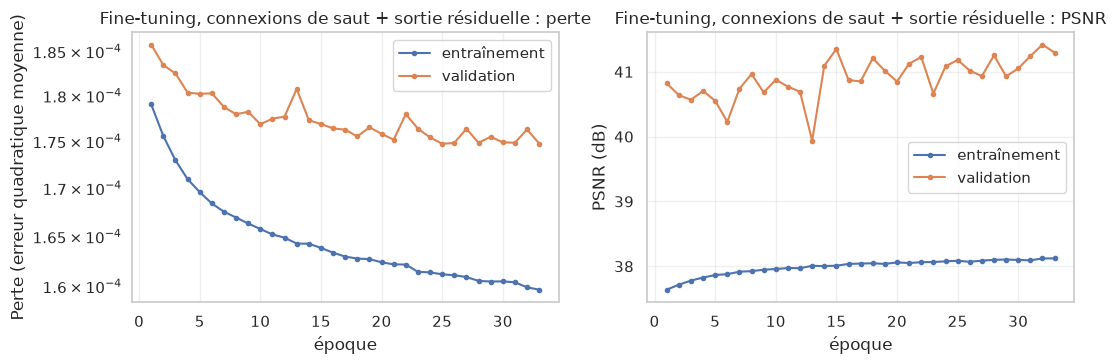

In [27]:
def fine_tuned(model, noisy_crops, clean_crops, val):
    """Copie de `model` (la version synthétique est gardée pour la comparaison), fine-tunée sur les recadrages donnés."""
    keras.utils.set_random_seed(config.SEED)
    tuned = keras.models.clone_model(model)
    tuned.set_weights(model.get_weights())
    hist = modeling.fine_tune(tuned, data.make_pair_dataset(noisy_crops, clean_crops), val, epochs=FT_EPOCHS, verbose=0)
    return tuned, hist


ft_models, ft_histories = {}, {}
t0 = time.perf_counter()
for name, model in models_.items():
    ft_models[name], ft_histories[name] = fine_tuned(model, mix_noisy, mix_clean, mix_val)
residual_name = "connexions de saut + sortie résiduelle"
real_only, _ = fine_tuned(models_[residual_name], ft_noisy, ft_clean, (data.to_float(rv_noisy), data.to_float(rv_clean)))
print(f"Fine-tuning de {len(ft_models) + 1} modèles en {(time.perf_counter() - t0) / 60:.1f} min")
ft_val = pd.Series({name: hist["val_psnr"].max() for name, hist in ft_histories.items()},
                   name="PSNR validation (recadrages mélangés)")
display(ft_val.to_frame())
final_name = ft_val.idxmax()
denoiser = ft_models[final_name]
evaluation.plot_history(ft_histories[final_name], f"Fine-tuning, {final_name}")
plt.show()

In [28]:
clean_test = [cls_data.read_rgb(p) for p in photo_paths["test"][:10 if QUICK else 50]]


def clean_psnr(model):
    """À quel point un modèle modifie des photos propres : PSNR de la sortie face à l'entrée, sur toutes les photos."""
    mse = np.mean([np.mean((modeling.denoise(model, c).astype(np.float64) - c) ** 2) for c in clean_test])
    return 10 * np.log10(255**2 / mse)


syn10 = data.to_float(np.stack([data.add_noise(p, 10, np.random.default_rng(config.SEED + 10)) for p in val_patches]))


def synthetic_gain(model):
    """Gain de PSNR sur les patchs de validation avec un bruit synthétique de sigma 10."""
    return evaluation.dataset_psnr(val_clean, modeling.predict(model, syn10)) - evaluation.dataset_psnr(val_clean, syn10)


FT = ", après fine-tuning"
REAL_ONLY = f"{residual_name}, fine-tuning sur les paires TouNum seules"
COL_CLEAN = "PSNR sur photos propres (sortie / entrée)"
COL_SYN = "gain sur bruit synthétique, sigma 10 (dB)"
all_models = {**models_, **{f"{n}{FT}": m for n, m in ft_models.items()}, REAL_ONLY: real_only}
clean_cols, syn_cols = {}, {}
for name, model in all_models.items():
    if name not in case_rows:
        case_rows[name] = real_scores([modeling.denoise(model, img) for img in test_noisy])
    clean_cols[name], syn_cols[name] = clean_psnr(model), synthetic_gain(model)
case = pd.DataFrame({name: {"PSNR": p.mean(), "SSIM": s.mean(), "images améliorées": (p > case_rows[NOISY][0]).mean()}
                     for name, (p, s) in case_rows.items()}).T
case[COL_CLEAN] = pd.Series(clean_cols)
case[COL_SYN] = pd.Series(syn_cols)
display(case)
final_psnr = case_rows[f"{final_name}{FT}"][0]
final_gain = final_psnr - case_rows[NOISY][0]
denoised_test = [modeling.denoise(denoiser, img) for img in test_noisy]

,PSNR,SSIM,images améliorées,PSNR sur photos propres (sortie / entrée),"gain sur bruit synthétique, sigma 10 (dB)"
bruitée (sans filtre),38.072,0.967,0.00,NaN,NaN
gaussien s=1,28.055,0.823,0.00,NaN,NaN
autoencodeur simple,32.542,0.918,0.00,29.882,4.706
autoencodeur + connexions de saut,37.033,0.963,0.04,38.744,9.283
connexions de saut + sortie résiduelle,37.391,0.965,0.00,41.569,9.599
"autoencodeur simple, après fine-tuning",34.268,0.939,0.00,31.728,6.014
"autoencodeur + connexions de saut, après fine-tuning",38.486,0.968,0.88,44.984,9.889
"connexions de saut + sortie résiduelle, après fine-tuning",38.750,0.969,0.98,48.970,10.231
"connexions de saut + sortie résiduelle, fine-tuning sur les paires TouNum seules",39.031,0.970,0.96,35.812,-2.007


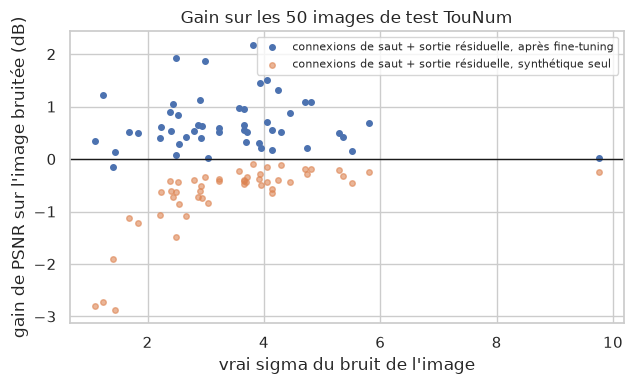

In [29]:
fig, ax = plt.subplots(figsize=(6.5, 4))
true_sigma = noisy_info.loc[test_idx, "true_sigma"].to_numpy()
ax.scatter(true_sigma, final_gain, s=16, label=f"{final_name}{FT}")
ax.scatter(true_sigma, case_rows[best_synth][0] - case_rows[NOISY][0], s=16, alpha=0.6,
           label=f"{best_synth}, synthétique seul")
ax.axhline(0, color="k", lw=1)
ax.set_xlabel("vrai sigma du bruit de l'image")
ax.set_ylabel("gain de PSNR sur l'image bruitée (dB)")
ax.set_title("Gain sur les 50 images de test TouNum")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

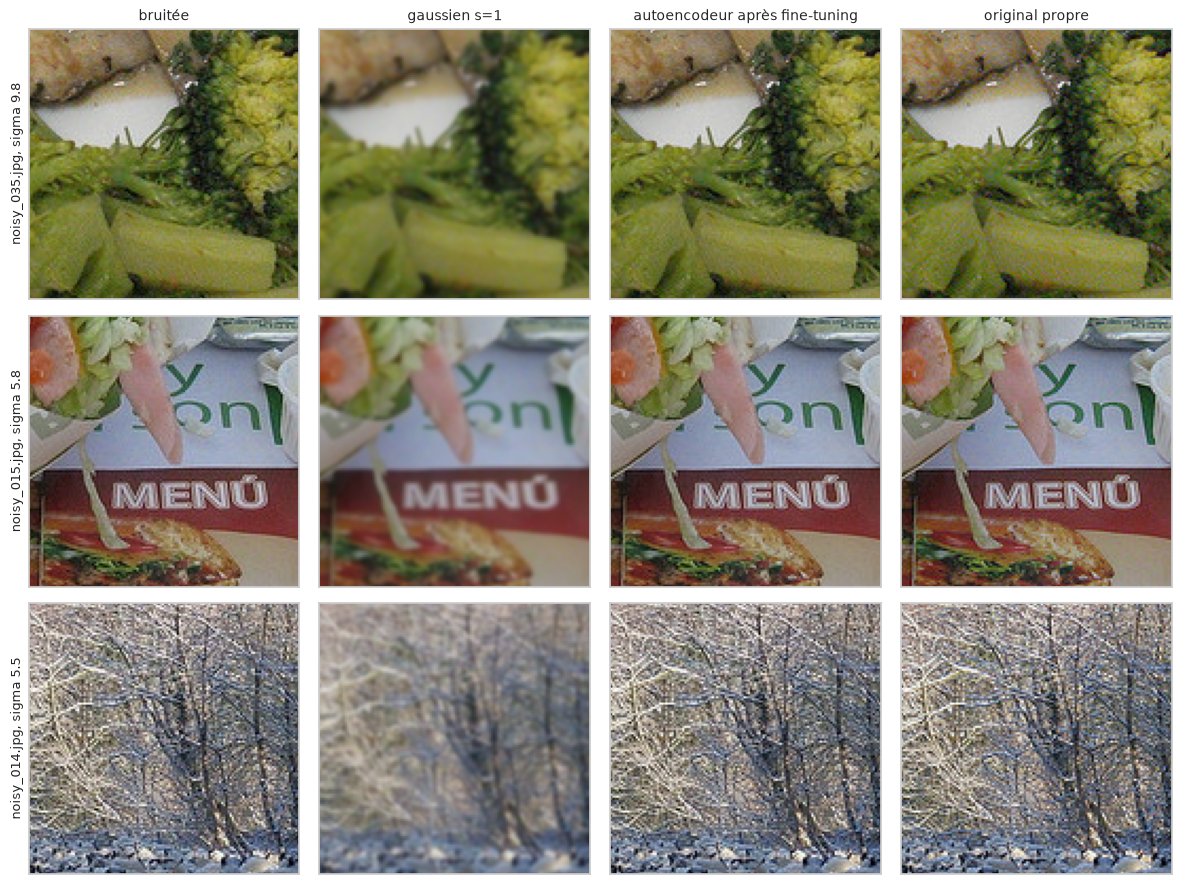

In [30]:
show = list(np.argsort(-true_sigma)[:3])
evaluation.show_grid({
    "bruitée": [center_crop(test_noisy[k], 128) for k in show],
    best_filter: [center_crop(filtered[k], 128) for k in show],
    "autoencodeur après fine-tuning": [center_crop(denoised_test[k], 128) for k in show],
    "original propre": [center_crop(test_orig[k], 128) for k in show],
}, [f"{noisy_info.file[test_idx[k]]}, sigma {true_sigma[k]:.1f}" for k in show], size=3)
plt.show()

In [31]:
ablation = case.loc[REAL_ONLY]
final_row = case.loc[f"{final_name}{FT}"]
display(Markdown(
    f"**Résultats.** Modèle retenu sur les recadrages de validation : **{final_name}**, après fine-tuning (PSNR de "
    f"validation {ft_val[final_name]:.2f} dB). Sur les 50 images de test, il fait passer le PSNR moyen de "
    f"**{case_rows[NOISY][0].mean():.2f}** à **{final_psnr.mean():.2f} dB** ({final_gain.mean():+.2f} dB) "
    f"et améliore **{(final_gain > 0).mean():.0%}** des images, contre {synth_table.loc[best_synth, 'PSNR']:.2f} dB "
    f"pour le meilleur modèle entraîné sur bruit synthétique seul. Versions fine-tunées des autres variantes : "
    + ", ".join(f"{n} {case.loc[f'{n}{FT}', 'PSNR']:.2f} dB" for n in ft_models if n != final_name) + ". "
    f"Sur des photos propres, le modèle retenu donne {final_row[COL_CLEAN]:.1f} dB, et sur un bruit synthétique de "
    f"sigma 10 il garde un gain de {final_row[COL_SYN]:+.1f} dB ({case.loc[final_name, COL_SYN]:+.1f} dB avant "
    f"fine-tuning). Fine-tuné sur les seules paires TouNum, le modèle résiduel atteint {ablation['PSNR']:.2f} dB sur "
    f"les images de test bruitées, mais {ablation[COL_CLEAN]:.1f} dB sur les photos propres et "
    f"{ablation[COL_SYN]:+.1f} dB sur le bruit synthétique : sans les deux parties supplémentaires, le fine-tuning "
    "spécialise le modèle sur le seul bruit TouNum."
))

**Résultats.** Modèle retenu sur les recadrages de validation : **connexions de saut + sortie résiduelle**, après fine-tuning (PSNR de validation 41.42 dB). Sur les 50 images de test, il fait passer le PSNR moyen de **38.07** à **38.75 dB** (+0.68 dB) et améliore **98%** des images, contre 37.39 dB pour le meilleur modèle entraîné sur bruit synthétique seul. Versions fine-tunées des autres variantes : autoencodeur simple 34.27 dB, autoencodeur + connexions de saut 38.49 dB. Sur des photos propres, le modèle retenu donne 49.0 dB, et sur un bruit synthétique de sigma 10 il garde un gain de +10.2 dB (+9.6 dB avant fine-tuning). Fine-tuné sur les seules paires TouNum, le modèle résiduel atteint 39.03 dB sur les images de test bruitées, mais 35.8 dB sur les photos propres et -2.0 dB sur le bruit synthétique : sans les deux parties supplémentaires, le fine-tuning spécialise le modèle sur le seul bruit TouNum.

### 9.3 Quand le pipeline doit-il débruiter ?
Un débruiteur ne peut pas ajouter d'information : sur une image déjà propre, il ne peut que modifier des détails.
En production, le pipeline ne sait pas quelles photos sont bruitées. La section 3.3 a montré que l'estimation à
l'aveugle est un signal faible à ce niveau de bruit : plutôt que de supposer un seuil, nous laissons les données de
validation trancher entre « ne jamais débruiter », « toujours débruiter » et « débruiter quand l'estimation vaut au
moins t », pour toutes les valeurs de t.

Le jeu de validation mélange les 20 vraies images de validation (bruitées) et 20 photos propres du jeu de
validation du livrable 1 : nous donnons donc le même poids aux photos bruitées et propres (TouNum ne nous a pas
indiqué la part de photos bruitées dans ses archives). Pour chaque image, le gain est la baisse de l'erreur
quadratique moyenne par rapport à la version propre, qui est aussi définie pour les images propres. La règle
retenue est celle qui a le plus grand gain moyen.

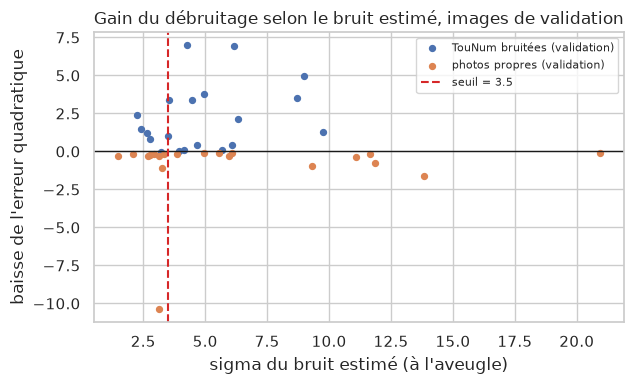

In [32]:
def mse_gain(noisy, clean):
    """Baisse de l'erreur quadratique moyenne (échelle 0-255) obtenue en débruitant une image."""
    before = np.mean((noisy.astype(np.float32) - clean) ** 2)
    after = np.mean((modeling.denoise(denoiser, noisy).astype(np.float32) - clean) ** 2)
    return before - after


def rule_table(noisy_list, clean_list):
    est = np.array([data.estimate_noise(img) for img in noisy_list])
    gains = np.array([mse_gain(n, c) for n, c in zip(noisy_list, clean_list)])
    return est, gains


n_clean = 5 if QUICK else 20
clean_val = [cls_data.read_rgb(p) for p in photo_paths["val"][:n_clean]]
val_est, val_gain = rule_table([noisy_images[i] for i in real_idx["val"]] + clean_val,
                               [originals[i] for i in real_idx["val"]] + clean_val)
candidates = np.concatenate([[0.0], np.sort(val_est), [np.inf]])
mean_gain = [np.where(val_est >= t, val_gain, 0).mean() for t in candidates]
NOISE_THRESHOLD = float(candidates[int(np.argmax(mean_gain))])
is_noisy_val = np.arange(len(val_est)) < len(real_idx["val"])

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(val_est[is_noisy_val], val_gain[is_noisy_val], s=18, label="TouNum bruitées (validation)")
ax.scatter(val_est[~is_noisy_val], val_gain[~is_noisy_val], s=18, label="photos propres (validation)")
ax.axhline(0, color="k", lw=1)
if np.isfinite(NOISE_THRESHOLD) and NOISE_THRESHOLD > 0:
    ax.axvline(NOISE_THRESHOLD, color="tab:red", ls="--", label=f"seuil = {NOISE_THRESHOLD:.1f}")
ax.set_xlabel("sigma du bruit estimé (à l'aveugle)")
ax.set_ylabel("baisse de l'erreur quadratique")
ax.set_title("Gain du débruitage selon le bruit estimé, images de validation")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [33]:
test_est, test_gain = rule_table(test_noisy + clean_test, test_orig + clean_test)
is_noisy_test = np.arange(len(test_est)) < len(test_noisy)
apply = test_est >= NOISE_THRESHOLD
rule_name = ("toujours débruiter" if NOISE_THRESHOLD == 0 else "ne jamais débruiter" if not np.isfinite(NOISE_THRESHOLD)
             else f"débruiter quand l'estimation vaut au moins {NOISE_THRESHOLD:.1f}")
display(Markdown(
    f"**Résultats.** Règle choisie sur les images de validation : **{rule_name}**. Sur les images de test "
    f"({is_noisy_test.sum()} images TouNum bruitées et {(~is_noisy_test).sum()} photos propres du jeu de test du "
    f"livrable 1), la baisse moyenne de l'erreur quadratique est de {np.where(apply, test_gain, 0).mean():+.2f} avec la "
    f"règle, {test_gain.mean():+.2f} en débruitant toujours et 0 en ne débruitant jamais. La règle débruite "
    f"{apply[is_noisy_test].mean():.0%} des images bruitées et {apply[~is_noisy_test].mean():.0%} des propres ; le "
    f"débruitage dégrade légèrement {(test_gain[~is_noisy_test] < 0).mean():.0%} des photos propres, avec une variation "
    f"moyenne de {test_gain[~is_noisy_test].mean():+.2f}, contre {test_gain[is_noisy_test].mean():+.2f} sur les "
    "bruitées."
))

**Résultats.** Règle choisie sur les images de validation : **débruiter quand l'estimation vaut au moins 3.5**. Sur les images de test (50 images TouNum bruitées et 50 photos propres du jeu de test du livrable 1), la baisse moyenne de l'erreur quadratique est de +0.21 avec la règle, +0.47 en débruitant toujours et 0 en ne débruitant jamais. La règle débruite 58% des images bruitées et 64% des propres ; le débruitage dégrade légèrement 100% des photos propres, avec une variation moyenne de -0.82, contre +1.76 sur les bruitées.

### 9.4 Le bruit gêne-t-il le filtre photo du livrable 1 ?
Le pipeline classe les images **avant** de les débruiter (seules les photos sont débruitées). Le filtre photo doit
donc lui-même supporter des entrées bruitées. Nous prenons le jeu de test du livrable 1 (photos et non-photos
jamais utilisées ici), ajoutons un bruit de couleur synthétique de plus en plus fort, et mesurons l'accuracy du
classifieur de production sauvegardé par le livrable 1, avec et sans débruitage préalable. Pour aller vite, nous
prenons 60 images par type et les réduisons à 320 pixels sur leur petit côté avant d'ajouter le bruit.

In [34]:
classifier_path = cls_config.MODELS_DIR / "photo_classifier.keras"
if QUICK and not classifier_path.exists():          # le livrable 1 n'a tourné qu'en mode quick
    classifier_path = Path(tempfile.gettempdir()) / "tounum_quick" / "photo_classifier.keras"
classifier = keras.models.load_model(classifier_path)
test_meta = meta[meta["split"] == "test"].groupby("source").sample(n=10 if QUICK else 60, random_state=config.SEED)
test_full = [data.downscale(cls_data.read_rgb(cls_config.PROJECT_ROOT / p), 320) for p in test_meta["path"]]
labels = test_meta["label"].to_numpy()

acc_rows = []
for s in (0, 10, 20):
    rng = np.random.default_rng(config.SEED + 100 + s)
    noisy_set = [data.add_noise(img, s, rng) if s else img for img in test_full]
    for variant, imgs in (("bruitée", noisy_set), ("débruitée d'abord", [modeling.denoise(denoiser, im) for im in noisy_set])):
        proba = cls_modeling.predict_proba(classifier, np.stack([cls_data.resize(im) for im in imgs]))
        pred = proba >= 0.5
        acc_rows.append({"sigma": s, "entrée": variant, "accuracy": (pred == labels).mean(),
                         "photos gardées": pred[labels == 1].mean(), "non-photos rejetées": (~pred[labels == 0]).mean()})
acc_df = pd.DataFrame(acc_rows)
display(acc_df.pivot(index="entrée", columns="sigma", values="accuracy").round(3))

sigma,0,10,20
entrée,,,
bruitée,0.967,0.947,0.943
débruitée d'abord,0.967,0.967,0.960


In [35]:
top = acc_df["sigma"].max()
acc_at = lambda s, variant: acc_df.loc[(acc_df["sigma"] == s) & (acc_df["entrée"] == variant), "accuracy"].iloc[0]
acc0, acc_top, acc_top_d = acc_at(0, "bruitée"), acc_at(top, "bruitée"), acc_at(top, "débruitée d'abord")
display(Markdown(
    f"**Résultats.** Sur {len(labels)} images de test ({labels.sum()} photos), l'accuracy du classifieur passe de "
    f"**{acc0:.3f}** sur les images d'origine à **{acc_top:.3f}** à sigma {top}, et à **{acc_top_d:.3f}** à sigma "
    f"{top} quand les images sont d'abord débruitées. "
    + ("Le filtre photo remarque à peine le bruit : les images sont réduites en 128×128 avant la classification, et "
       "cette réduction moyenne l'essentiel du bruit. Classer avant de débruiter ne pose donc pas de problème."
       if acc0 - acc_top < 0.03 else
       "Un bruit fort gêne bien le filtre photo. Pour des archives très bruitées, il vaudrait la peine de débruiter "
       "toutes les images avant de les classer, ou d'entraîner le classifieur avec une augmentation par bruit.")
))

**Résultats.** Sur 300 images de test (60 photos), l'accuracy du classifieur passe de **0.967** sur les images d'origine à **0.943** à sigma 20, et à **0.960** à sigma 20 quand les images sont d'abord débruitées. Le filtre photo remarque à peine le bruit : les images sont réduites en 128×128 avant la classification, et cette réduction moyenne l'essentiel du bruit. Classer avant de débruiter ne pose donc pas de problème.

### 9.5 Sauvegarde du débruiteur
Le fichier de réglages garde la règle de décision et les noms des 50 images de test, pour que le livrable 3 puisse
mesurer les légendes sur des images TouNum que le débruiteur n'a jamais vues.

In [36]:
SAVE_DIR = Path(tempfile.gettempdir()) / "tounum_quick" if QUICK else config.MODELS_DIR
SAVE_DIR.mkdir(parents=True, exist_ok=True)
denoiser.save(SAVE_DIR / "denoiser.keras")
settings = {"model": f"{final_name}{FT}", "noise_threshold": NOISE_THRESHOLD,
            "pad_multiple": modeling.PAD_MULTIPLE, "test_files": real_split["test"]}
(SAVE_DIR / "denoiser.json").write_text(json.dumps(settings, indent=2, ensure_ascii=False))
reloaded = keras.models.load_model(SAVE_DIR / "denoiser.keras")
assert np.array_equal(modeling.denoise(reloaded, test_noisy[0]), denoised_test[0])
shown = SAVE_DIR.relative_to(config.PROJECT_ROOT) if SAVE_DIR.is_relative_to(config.PROJECT_ROOT) else SAVE_DIR
print(f"Sauvegardés : {shown}/denoiser.keras ({(SAVE_DIR / 'denoiser.keras').stat().st_size / 1e6:.1f} Mo) et "
      f"{shown}/denoiser.json (modèle : {settings['model']}, seuil : {NOISE_THRESHOLD}), rechargement vérifié.")

Sauvegardés : models/denoiser.keras (5.7 Mo) et models/denoiser.json (modèle : connexions de saut + sortie résiduelle, après fine-tuning, seuil : 3.4879752727887166), rechargement vérifié.


Utilisation en production (c'est ce que fait le pipeline du livrable 3) :
```python
from tounum_denoise import data, modeling
denoiser = keras.models.load_model("models/denoiser.keras")
settings = json.load(open("models/denoiser.json"))
img = cls_data.read_rgb("photo.jpg")                       # RGB uint8, toute taille
if data.estimate_noise(img) >= settings["noise_threshold"]:
    img = modeling.denoise(denoiser, img)                  # RGB uint8, même taille
```

## 10. Conclusion, limites et suites

In [37]:
display(Markdown(
    f"**Synthèse.** Modèle retenu : **{final_name}**, entraîné sur bruit de couleur synthétique puis fine-tuné sur 78 "
    f"paires réelles, des photos propres et du bruit synthétique ({milliers(denoiser.count_params())} paramètres). Sur "
    f"les 50 images de test TouNum : {case_rows[NOISY][0].mean():.2f} dB avant, {final_psnr.mean():.2f} dB après "
    f"({(final_gain > 0).mean():.0%} des images améliorées), contre {synth_table.loc[best_synth, 'PSNR']:.2f} dB avec "
    f"l'entraînement synthétique seul et {synth_table.loc[best_filter, 'PSNR']:.2f} dB pour le meilleur filtre "
    f"classique. Règle du pipeline : {rule_name}."
))

**Synthèse.** Modèle retenu : **connexions de saut + sortie résiduelle**, entraîné sur bruit de couleur synthétique puis fine-tuné sur 78 paires réelles, des photos propres et du bruit synthétique (466 595 paramètres). Sur les 50 images de test TouNum : 38.07 dB avant, 38.75 dB après (98% des images améliorées), contre 37.39 dB avec l'entraînement synthétique seul et 28.05 dB pour le meilleur filtre classique. Règle du pipeline : débruiter quand l'estimation vaut au moins 3.5.

### Ce que nous avons construit
1. Le code de chargement du dataset TouNum, et la découverte des **originaux propres** des 148 images bruitées, qui
   a transformé un exercice qualitatif en un exercice mesuré.
2. Une **analyse du vrai bruit** : il ne touche que les couleurs, il est légèrement flou, délave un peu les
   couleurs et il est plus fort sur les couleurs saturées ; nous avons construit un bruit de couleur synthétique
   qui s'en approche.
3. Une **comparaison** entre les filtres de convolution classiques et trois autoencodeurs convolutifs (simple, avec
   connexions de saut, avec sortie résiduelle), par niveau de bruit et sur les vraies images.
4. Une **étape de fine-tuning sur paires réelles, photos propres et bruit synthétique**, mesurée sur 50 vraies
   images mises de côté, qui rend l'autoencodeur utile sur le bruit de TouNum tout en laissant les photos propres
   presque intactes et en gardant son gain sur des bruits plus forts.
5. Une **règle de décision** pour le pipeline, choisie sur des données de validation et vérifiée sur des images de
   test, et la vérification que le **filtre photo du livrable 1** fonctionne encore sur des images bruitées.
6. Un **modèle sauvegardé** (`models/denoiser.keras`) et ses réglages (`models/denoiser.json`).

### Limites
- **Vrai bruit léger** : les 148 images ne sont que légèrement bruitées (autour de 38 dB), donc le gain mesurable
  est faible en valeur absolue.
- **Un seul type de bruit** : le modèle a appris le bruit de couleur de TouNum plus le JPEG. Les autres
  dégradations de la numérisation (flou, traînées de scanner, moiré, gros blocs JPEG, poussières) ne sont pas
  traitées et demanderaient leurs propres données d'entraînement.
- **Peu de paires réelles** : le fine-tuning utilise 78 images et le test 50. Plus de paires, venant d'autres
  scanners, rendraient la mesure plus précise et le modèle plus robuste.
- **Décision à l'aveugle** : à ce niveau de bruit, l'estimation à l'aveugle sépare mal les photos bruitées et
  propres. La règle de la section 9.3 a été choisie sur un mélange 50/50 de photos bruitées et propres ; une part
  très différente de photos bruitées dans les archives pourrait demander une autre règle. Si TouNum sait quels lots
  viennent d'un scanner bruité, cette information serait le signal le plus fiable.
- **Le PSNR et le SSIM ne sont pas le but final** : ce qui compte pour TouNum, c'est la légende. Le livrable 3
  mesure l'effet du bruit et du débruitage sur la qualité des légendes.

### Suites possibles
- Ajouter le flou aux dégradations d'entraînement (défloutage), puisque l'énoncé mentionne aussi des scans flous ;
- collecter davantage de vraies paires (bruitée, propre) sur les propres scanners de TouNum pour enrichir le jeu de
  fine-tuning ;
- modéliser la perte de saturation et le bruit dépendant de la saturation dans le bruit synthétique, ce qui
  réduirait le besoin de paires réelles ;
- mesurer l'effet sur les légendes de bout en bout (livrable 3).